In [1]:
 # !pip install --quiet scikit-learn xgboost shap joblib pandas numpy matplotlib seaborn

In [40]:
import os
import sys
import glob
import json
import warnings
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import joblib

try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False

warnings.filterwarnings("ignore")
%matplotlib inline

In [41]:
import os
import tarfile

archive_path = r"C:\CERT\r4.2.tar.bz2"

print(os.path.exists(archive_path))

True


In [7]:
# import os
# import tarfile

# archive_path = r"C:\CERT\r4.2.tar.bz2"
# extract_path = r"C:\CERT\extracted"

# os.makedirs(extract_path, exist_ok=True)
# # 
# with tarfile.open(archive_path, "r:bz2") as tar:
#     tar.extractall(extract_path)

# print("Extraction completed.")
# print(extract_path)

Extraction completed.
C:\CERT\extracted


In [23]:
# import os
# import tarfile

# answers_archive = r"C:\CERT\answers.tar.bz2"
# answers_extract_path = r"C:\CERT\answers"

# # print("Archive exists:", os.path.exists(answers_archive))

# if not os.path.exists(answers_archive):
#     raise FileNotFoundError(
#         f"answers.tar.bz2 not found at: {answers_archive}"
#     )

# os.makedirs(answers_extract_path, exist_ok=True)

# with tarfile.open(answers_archive, "r:bz2") as tar:
#     tar.extractall(answers_extract_path)

# print("Answers extraction completed.")
# print("Location:", answers_extract_path)

Archive exists: True
Answers extraction completed.
Location: C:\CERT\answers


In [4]:
for root, dirs, files in os.walk(r"C:\CERT\answers"):
    print(root)
    for file in files:
        print("   ", file)

C:\CERT\answers
C:\CERT\answers\answers
    insiders.csv
    license.txt
    r2.csv
    r3.1-1.csv
    r3.1-2.csv
    r3.2-1.csv
    r3.2-2.csv
    r4.1-1.csv
    r4.1-2.csv
    r4.1-3.csv
    r5.1-1.csv
    r5.1-2.csv
    r5.1-3.csv
    r5.1-4.csv
    r6.1-1.csv
    r6.1-2.csv
    r6.1-3.csv
    r6.1-5.csv
    r6.2-1.csv
    r6.2-2.csv
    r6.2-3.csv
    r6.2-4.csv
    r6.2-5.csv
    readme.txt
    scenarios.txt
C:\CERT\answers\answers\r4.2-1
    r4.2-1-AAM0658.csv
    r4.2-1-AJR0932.csv
    r4.2-1-BDV0168.csv
    r4.2-1-BIH0745.csv
    r4.2-1-BLS0678.csv
    r4.2-1-BTL0226.csv
    r4.2-1-CAH0936.csv
    r4.2-1-DCH0843.csv
    r4.2-1-EHB0824.csv
    r4.2-1-EHD0584.csv
    r4.2-1-FMG0527.csv
    r4.2-1-FTM0406.csv
    r4.2-1-GHL0460.csv
    r4.2-1-HJB0742.csv
    r4.2-1-JMB0308.csv
    r4.2-1-JRG0207.csv
    r4.2-1-KLH0596.csv
    r4.2-1-KPC0073.csv
    r4.2-1-LJR0523.csv
    r4.2-1-LQC0479.csv
    r4.2-1-MAR0955.csv
    r4.2-1-MAS0025.csv
    r4.2-1-MCF0600.csv
    r4.2-1-MYD0978.csv


In [8]:
DATA_SEARCH_DIRS = [
    r"C:\CERT\extracted\r4.2"
]

def inspect_runtime_environment(search_dirs: List[str]) -> List[Dict[str, Any]]:
    discovered_files = []
    supported_extensions = ("*.csv", "*.parquet", "*.json", "*.txt", "*.tar.gz", "*.tar.bz2", "*.zip")
    
    for directory in search_dirs:
        if not os.path.exists(directory):
            continue
        for ext in supported_extensions:
            for filepath in glob.glob(os.path.join(directory, "**", ext), recursive=True):
                if "/." in filepath or "\\." in filepath or ".ipynb_checkpoints" in filepath:
                    continue
                size_mb = os.path.getsize(filepath) / (1024 * 1024)
                discovered_files.append({
                    "path": filepath,
                    "filename": os.path.basename(filepath),
                    "size_mb": round(size_mb, 2),
                    "extension": Path(filepath).suffix.lower()
                })
    return discovered_files

all_files = inspect_runtime_environment(DATA_SEARCH_DIRS)

if not all_files:
    raise FileNotFoundError(
        "CRITICAL ERROR: No CERT dataset files detected."
    )

files_df = pd.DataFrame(all_files).drop_duplicates(subset=["path"])

print(f"Discovered {len(files_df)} candidate file(s):")
display(files_df[["filename", "size_mb", "extension", "path"]])

print("\n=== Dataset Schema Inspection (First 3 Rows) ===")

for _, row in files_df[files_df["extension"] == ".csv"].head(10).iterrows():
    try:
        sample_df = pd.read_csv(row["path"], nrows=3)
        print(f"\nFile: {row['filename']} (Size: {row['size_mb']} MB)")
        print(f"Columns ({len(sample_df.columns)}): {list(sample_df.columns)}")
        print("Sample Data:")
        display(sample_df.head(2))
    except Exception as e:
        print(f"Could not preview {row['filename']}: {e}")

Discovered 26 candidate file(s):


,filename,size_mb,extension,path
0,device.csv,27.64,.csv,C:\CERT\extracted\r4.2\device.csv
1,email.csv,616.84,.csv,C:\CERT\extracted\r4.2\email.csv
2,file.csv,184.11,.csv,C:\CERT\extracted\r4.2\file.csv
3,http.csv,13862.86,.csv,C:\CERT\extracted\r4.2\http.csv
4,logon.csv,55.80,.csv,C:\CERT\extracted\r4.2\logon.csv
5,psychometric.csv,0.04,.csv,C:\CERT\extracted\r4.2\psychometric.csv
6,2009-12.csv,0.14,.csv,C:\CERT\extracted\r4.2\LDAP\2009-12.csv
7,2010-01.csv,0.14,.csv,C:\CERT\extracted\r4.2\LDAP\2010-01.csv
8,2010-02.csv,0.14,.csv,C:\CERT\extracted\r4.2\LDAP\2010-02.csv
9,2010-03.csv,0.14,.csv,C:\CERT\extracted\r4.2\LDAP\2010-03.csv



=== Dataset Schema Inspection (First 3 Rows) ===

File: device.csv (Size: 27.64 MB)
Columns (5): ['id', 'date', 'user', 'pc', 'activity']
Sample Data:


,id,date,user,pc,activity
0,{J1S3-L9UU75BQ-7790ATPL},01/02/2010 07:21:06,MOH0273,PC-6699,Connect
1,{N7B5-Y7BB27SI-2946PUJK},01/02/2010 07:37:41,MOH0273,PC-6699,Disconnect



File: email.csv (Size: 616.84 MB)
Columns (11): ['id', 'date', 'user', 'pc', 'to', 'cc', 'bcc', 'from', 'size', 'attachments', 'content']
Sample Data:


...

,employee_name,user_id,email,role,business_unit,functional_unit,department,team,supervisor
0,Calvin Edan Love,CEL0561,Calvin.Edan.Love@dtaa.com,ComputerProgrammer,1,2 - ResearchAndEngineering,2 - SoftwareManagement,3 - Software,Stephanie Briar Harrington
1,Christine Reagan Deleon,CRD0624,Christine.Reagan.Deleon@dtaa.com,Salesman,1,5 - SalesAndMarketing,2 - Sales,3 - RegionalSales,Winter Veda Burks



File: 2010-02.csv (Size: 0.14 MB)
Columns (9): ['employee_name', 'user_id', 'email', 'role', 'business_unit', 'functional_unit', 'department', 'team', 'supervisor']
Sample Data:


,employee_name,user_id,email,role,business_unit,functional_unit,department,team,supervisor
0,Calvin Edan Love,CEL0561,Calvin.Edan.Love@dtaa.com,ComputerProgrammer,1,2 - ResearchAndEngineering,2 - SoftwareManagement,3 - Software,Stephanie Briar Harrington
1,Christine Reagan Deleon,CRD0624,Christine.Reagan.Deleon@dtaa.com,Salesman,1,5 - SalesAndMarketing,2 - Sales,3 - RegionalSales,Winter Veda Burks



File: 2010-03.csv (Size: 0.14 MB)
Columns (9): ['employee_name', 'user_id', 'email', 'role', 'business_unit', 'functional_unit', 'department', 'team', 'supervisor']
Sample Data:


,employee_name,user_id,email,role,business_unit,functional_unit,department,team,supervisor
0,Calvin Edan Love,CEL0561,Calvin.Edan.Love@dtaa.com,ComputerProgrammer,1,2 - ResearchAndEngineering,2 - SoftwareManagement,3 - Software,Stephanie Briar Harrington
1,Jade Felicia Caldwell,JFC0557,Jade.Felicia.Caldwell@dtaa.com,SoftwareEngineer,1,2 - ResearchAndEngineering,2 - SoftwareManagement,3 - Software,Stephanie Briar Harrington


In [9]:
available_filenames = {
    os.path.basename(f["path"]).lower(): f["path"]
    for f in all_files
}

cert_file_map = {}

for fname, fpath in available_filenames.items():
    if "logon" in fname:
        cert_file_map["logon"] = fpath
    elif "device" in fname or "usb" in fname:
        cert_file_map["device"] = fpath
    elif "http" in fname or "web" in fname:
        cert_file_map["http"] = fpath
    elif "file" in fname:
        cert_file_map["file"] = fpath
    elif "email" in fname:
        cert_file_map["email"] = fpath
    elif "user" in fname or "ldap" in fname:
        cert_file_map["users"] = fpath

answers_path = r"C:\CERT\answers\answers\insiders.csv"

if os.path.exists(answers_path):
    cert_file_map["answers"] = answers_path
else:
    raise FileNotFoundError(
        f"Official CERT answer key not found: {answers_path}"
    )

print("Resolved CERT dataset components:")

for component, path in cert_file_map.items():
    print(f" - {component}: {path}")

if not cert_file_map:
    raise ValueError(
        "No compatible CERT activity logs found."
    )

Resolved CERT dataset components:
 - device: C:\CERT\extracted\r4.2\device.csv
 - email: C:\CERT\extracted\r4.2\email.csv
 - file: C:\CERT\extracted\r4.2\file.csv
 - http: C:\CERT\extracted\r4.2\http.csv
 - logon: C:\CERT\extracted\r4.2\logon.csv
 - answers: C:\CERT\answers\answers\insiders.csv


In [10]:
def load_csv_safely(filepath: str, nrows: Optional[int] = None) -> pd.DataFrame:
    """Loads CSV with consistent timestamp parsing and type casting."""
    print(f"Loading: {os.path.basename(filepath)} ...")
    df = pd.read_csv(filepath, nrows=nrows)
    
    df.columns = [c.strip().lower() for c in df.columns]
    
    for col in df.columns:
        if any(term in col for term in ["date", "time", "timestamp"]):
            try:
                df[col] = pd.to_datetime(df[col], errors="coerce")
                print(f" - Converted '{col}' to datetime format.")
            except Exception:
                pass
    return df

loaded_tables = {}
for comp_name, comp_path in cert_file_map.items():
    loaded_tables[comp_name] = load_csv_safely(comp_path)
    print(f" Loaded '{comp_name}' -> Shape: {loaded_tables[comp_name].shape}")

Loading: device.csv ...
 - Converted 'date' to datetime format.
 Loaded 'device' -> Shape: (405380, 5)
Loading: email.csv ...
 - Converted 'date' to datetime format.
 Loaded 'email' -> Shape: (2543116, 11)
Loading: file.csv ...
 - Converted 'date' to datetime format.
 Loaded 'file' -> Shape: (445581, 6)
Loading: http.csv ...
 - Converted 'date' to datetime format.
 Loaded 'http' -> Shape: (28434423, 6)
Loading: logon.csv ...
 - Converted 'date' to datetime format.
 Loaded 'logon' -> Shape: (854859, 5)
Loading: insiders.csv ...
 Loaded 'answers' -> Shape: (191, 6)


In [29]:
answers_df = loaded_tables["answers"]

print(f"Ground-truth answers file loaded with {len(answers_df):,} records.")
print("Answers columns:")
print(list(answers_df.columns))

display(answers_df.head(10))

Ground-truth answers file loaded with 191 records.
Answers columns:
['dataset', 'scenario', 'details', 'user', 'start', 'end']


,dataset,scenario,details,user,start,end
0,2.0,1,r2.csv,ONS0995,3/6/2010 1:41:56,3/20/2010 8:10:12
1,3.1,1,r3.1-1.csv,CSF0929,07/01/2010 01:24:58,07/16/2010 06:52:00
2,3.1,2,r3.1-2.csv,CCH0959,08/02/2010 10:34:31,09/30/2010 15:04:03
3,3.2,1,r3.2-1.csv,RCW0822,09/29/2010 21:10:27,10/15/2010 06:34:52
4,3.2,2,r3.2-2.csv,JCE0258,07/12/2010 08:16:02,09/03/2010 16:16:29
5,4.1,1,r4.1-1.csv,ABB0427,08/21/2010 05:20:34,08/27/2010 05:39:51
6,4.1,2,r4.1-2.csv,HFC0492,08/23/2010 10:40:56,10/14/2010 17:11:42
7,4.1,3,r4.1-3.csv,KTW0365,07/08/2010 11:51:00,07/09/2010 20:54:16
8,4.2,1,r4.2-1-AAM0658.csv,AAM0658,10/23/2010 01:34:19,10/29/2010 05:23:28
9,4.2,1,r4.2-1-AJR0932.csv,AJR0932,09/10/2010 19:12:01,09/18/2010 02:02:51


In [39]:
PRIMARY_LABEL_COL = "label"

answers_df = loaded_tables["answers"].copy()

print(f"Ground-truth answers file loaded with {len(answers_df):,} records.")
print("Answers schema:", list(answers_df.columns))

answers_df["dataset"] = answers_df["dataset"].astype(str).str.strip()

r42_answers = answers_df[
    answers_df["dataset"].isin(["4.2", "4.2.0"])
].copy()

print(f"\nr4.2 ground-truth scenarios: {len(r42_answers)}")

display(r42_answers)

r42_answers["user"] = r42_answers["user"].astype(str).str.strip()
r42_answers["start"] = pd.to_datetime(r42_answers["start"], errors="coerce")
r42_answers["end"] = pd.to_datetime(r42_answers["end"], errors="coerce")

if "logon" not in loaded_tables:
    raise ValueError("logon.csv is not loaded.")

activity_df = loaded_tables["logon"].copy()
primary_source = "logon"

user_col = next(
    (c for c in activity_df.columns if "user" in c),
    None
)

date_col = next(
    (c for c in activity_df.columns
     if any(t in c for t in ["date", "time", "timestamp"])),
    None
)

if not user_col or not date_col:
    raise KeyError(
        f"Unable to detect required user or datetime columns in {primary_source}."
    )

print(f"\nBase activity dataset selected: '{primary_source}' with {len(activity_df):,} events.")
print(f"User entity column: '{user_col}'")
print(f"Timestamp column: '{date_col}'")

activity_df[user_col] = activity_df[user_col].astype(str).str.strip()
activity_df[date_col] = pd.to_datetime(activity_df[date_col], errors="coerce")

activity_df["target"] = 0

for _, incident in r42_answers.iterrows():
    incident_user = incident["user"]
    incident_start = incident["start"]
    incident_end = incident["end"]

    if pd.isna(incident_start) or pd.isna(incident_end):
        continue

    mask = (
        (activity_df[user_col] == incident_user) &
        (activity_df[date_col] >= incident_start) &
        (activity_df[date_col] <= incident_end)
    )

    activity_df.loc[mask, "target"] = 1

loaded_tables["logon"] = activity_df.copy()

class_dist = activity_df["target"].value_counts(normalize=True).to_dict()

print("\nGround Truth Target Distribution:")
print(
    f" - Class 0 (Normal): "
    f"{activity_df['target'].value_counts().get(0, 0):,} "
    f"({class_dist.get(0, 0.0):.4%})"
)
print(
    f" - Class 1 (Insider Threat): "
    f"{activity_df['target'].value_counts().get(1, 0):,} "
    f"({class_dist.get(1, 0.0):.4%})"
)

print(f"\nTarget column persisted: {'target' in loaded_tables['logon'].columns}")

Ground-truth answers file loaded with 191 records.
Answers schema: ['dataset', 'scenario', 'details', 'user', 'start', 'end']

r4.2 ground-truth scenarios: 70


,dataset,scenario,details,user,start,end
8,4.2,1,r4.2-1-AAM0658.csv,AAM0658,10/23/2010 01:34:19,10/29/2010 05:23:28
9,4.2,1,r4.2-1-AJR0932.csv,AJR0932,09/10/2010 19:12:01,09/18/2010 02:02:51
10,4.2,1,r4.2-1-BDV0168.csv,BDV0168,07/30/2010 19:56:44,08/10/2010 05:16:41
11,4.2,1,r4.2-1-BIH0745.csv,BIH0745,07/13/2010 20:15:23,07/13/2010 21:20:44
12,4.2,1,r4.2-1-BLS0678.csv,BLS0678,09/21/2010 01:16:22,09/30/2010 04:48:19
...,...,...,...,...,...,...
73,4.2,3,r4.2-3-JGT0221.csv,JGT0221,07/15/2010 09:43:23,07/16/2010 19:33:29
74,4.2,3,r4.2-3-JLM0364.csv,JLM0364,04/28/2011 09:50:07,04/29/2011 20:04:27
75,4.2,3,r4.2-3-JTM0223.csv,JTM0223,07/22/2010 07:27:46,07/23/2010 18:01:20
76,4.2,3,r4.2-3-MPM0220.csv,MPM0220,11/04/2010 08:59:55,11/05/2010 19:29:06



Base activity dataset selected: 'logon' with 854,859 events.
User entity column: 'user'
Timestamp column: 'date'

Ground Truth Target Distribution:
 - Class 0 (Normal): 851,411 (99.5967%)
 - Class 1 (Insider Threat): 3,448 (0.4033%)

Target column persisted: True


In [40]:
print("target exists:", "target" in activity_df.columns)
print("activity_df shape:", activity_df.shape)
print("target values:", activity_df["target"].value_counts().to_dict() if "target" in activity_df.columns else "MISSING")

target exists: True
activity_df shape: (854859, 6)
target values: {0: 851411, 1: 3448}


In [41]:
print("target exists:", "target" in activity_df.columns)
print("columns:", len(activity_df.columns))

target exists: True
columns: 6


In [42]:
if "logon" not in loaded_tables:
    raise ValueError("logon.csv is not loaded.")

activity_df = loaded_tables["logon"].copy()

user_col = next(
    (c for c in activity_df.columns if "user" in c),
    None
)

date_col = next(
    (c for c in activity_df.columns if any(t in c for t in ["date", "time", "timestamp"])),
    None
)

if not user_col:
    raise KeyError("Unable to detect user column in logon data.")

if not date_col:
    raise KeyError("Unable to detect datetime column in logon data.")

activity_df = activity_df.sort_values(
    by=date_col
).reset_index(drop=True)

drop_cols = [
    c for c in ["id", "index", "unnamed: 0"]
    if c in activity_df.columns
]

if drop_cols:
    activity_df = activity_df.drop(columns=drop_cols)

activity_df["hour"] = activity_df[date_col].dt.hour
activity_df["day_of_week"] = activity_df[date_col].dt.dayofweek
activity_df["is_weekend"] = activity_df["day_of_week"].isin([5, 6]).astype(int)
activity_df["is_off_hours"] = (
    (activity_df["hour"] < 7) |
    (activity_df["hour"] >= 19)
).astype(int)

activity_col = next(
    (c for c in activity_df.columns if c in ["activity", "action", "type", "operation"]),
    None
)

pc_col = next(
    (c for c in activity_df.columns if c in ["pc", "device", "computer", "machine"]),
    None
)

if activity_col:
    activity_df[activity_col] = (
        activity_df[activity_col]
        .astype(str)
        .str.strip()
        .str.lower()
    )
    print(f"Identified activity action types: {activity_df[activity_col].unique().tolist()}")

if pc_col:
    activity_df[pc_col] = (
        activity_df[pc_col]
        .astype(str)
        .str.strip()
    )

print(f"User column: {user_col}")
print(f"Timestamp column: {date_col}")
print(f"Data cleaned. Total clean events: {len(activity_df):,}")

Identified activity action types: ['logon', 'logoff']
User column: user
Timestamp column: date
Data cleaned. Total clean events: 854,859


In [43]:
baseline_feature_cols = ["hour", "day_of_week", "is_weekend", "is_off_hours"]

if activity_col:
    action_dummies = pd.get_dummies(
        activity_df[activity_col],
        prefix="action",
        drop_first=True
    )
    baseline_feature_cols.extend(action_dummies.columns.tolist())
    activity_df = pd.concat([activity_df, action_dummies], axis=1)

print(f"Baseline Features ({len(baseline_feature_cols)}): {baseline_feature_cols}")

print("Computing leakage-safe expanding behavioral features per user entity...")

activity_df = activity_df.sort_values(
    by=[user_col, date_col]
).reset_index(drop=True)

activity_df["user_historical_event_count"] = (
    activity_df.groupby(user_col).cumcount()
)

previous_off_hours = (
    activity_df.groupby(user_col)["is_off_hours"]
    .cumsum()
    .sub(activity_df["is_off_hours"])
)

previous_weekend = (
    activity_df.groupby(user_col)["is_weekend"]
    .cumsum()
    .sub(activity_df["is_weekend"])
)

activity_df["user_off_hours_ratio"] = np.where(
    activity_df["user_historical_event_count"] > 0,
    previous_off_hours / activity_df["user_historical_event_count"],
    0.0
)

activity_df["user_weekend_ratio"] = np.where(
    activity_df["user_historical_event_count"] > 0,
    previous_weekend / activity_df["user_historical_event_count"],
    0.0
)

if pc_col:
    activity_df["user_distinct_pc_count"] = (
        activity_df.groupby(user_col)[pc_col]
        .transform(
            lambda s: s.where(
                ~s.duplicated(),
                np.nan
            ).notna().cumsum()
        )
    )
else:
    activity_df["user_distinct_pc_count"] = 1

activity_df["time_since_last_action_min"] = (
    activity_df.groupby(user_col)[date_col]
    .diff()
    .dt.total_seconds()
    .div(60.0)
    .fillna(0.0)
    .clip(0, 1440)
)

activity_df["is_rapid_burst"] = (
    activity_df["time_since_last_action_min"] < 1.0
).astype(int)

enhanced_feature_cols = baseline_feature_cols + [
    "user_historical_event_count",
    "user_off_hours_ratio",
    "user_weekend_ratio",
    "user_distinct_pc_count",
    "time_since_last_action_min",
    "is_rapid_burst"
]

activity_df[enhanced_feature_cols] = (
    activity_df[enhanced_feature_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0.0)
)

print(
    f"Enhanced Features ({len(enhanced_feature_cols)}): "
    f"{enhanced_feature_cols}"
)

Baseline Features (5): ['hour', 'day_of_week', 'is_weekend', 'is_off_hours', 'action_logon']
Computing leakage-safe expanding behavioral features per user entity...
Enhanced Features (11): ['hour', 'day_of_week', 'is_weekend', 'is_off_hours', 'action_logon', 'user_historical_event_count', 'user_off_hours_ratio', 'user_weekend_ratio', 'user_distinct_pc_count', 'time_since_last_action_min', 'is_rapid_burst']


In [44]:

# RESEARCH NOTE: To prevent temporal data leakage in time-series insider threat detection,
# we strictly use a chronological time-aware split rather than a random shuffle.
# Train (70%), Validation (15%), Test (15%) partitioned by actual event occurrence time.

# Re-sort strictly by time
activity_df = activity_df.sort_values(by=date_col).reset_index(drop=True)

total_rows = len(activity_df)
train_idx = int(total_rows * 0.70)
val_idx = int(total_rows * 0.85)

train_df = activity_df.iloc[:train_idx]
val_df = activity_df.iloc[train_idx:val_idx]
test_df = activity_df.iloc[val_idx:]

print("Temporal Split Details:")
print(f" - Train set:      {len(train_df):,} records ({train_df[date_col].min()} to {train_df[date_col].max()})")
print(f" - Validation set: {len(val_df):,} records ({val_df[date_col].min()} to {val_df[date_col].max()})")
print(f" - Test set:       {len(test_df):,} records ({test_df[date_col].min()} to {test_df[date_col].max()})")

print(f"\nPositive Target Count per Split:")
print(f" - Train: {train_df['target'].sum()} threats ({train_df['target'].mean():.4%})")
print(f" - Val:   {val_df['target'].sum()} threats ({val_df['target'].mean():.4%})")
print(f" - Test:  {test_df['target'].sum()} threats ({test_df['target'].mean():.4%})")

# Feature slices for training
X_train_base = train_df[baseline_feature_cols].values
X_val_base = val_df[baseline_feature_cols].values
X_test_base = test_df[baseline_feature_cols].values

X_train_enh = train_df[enhanced_feature_cols].values
X_val_enh = val_df[enhanced_feature_cols].values
X_test_enh = test_df[enhanced_feature_cols].values

y_train = train_df["target"].values
y_val = val_df["target"].values
y_test = test_df["target"].values



Temporal Split Details:
 - Train set:      598,401 records (2010-01-02 06:49:00 to 2010-12-03 07:51:00)
 - Validation set: 128,229 records (2010-12-03 07:51:00 to 2011-02-23 12:34:14)
 - Test set:       128,229 records (2011-02-23 12:34:26 to 2011-05-17 06:43:35)

Positive Target Count per Split:
 - Train: 2483 threats (0.4149%)
 - Val:   601 threats (0.4687%)
 - Test:  364 threats (0.2839%)


In [45]:

# Supervised Random Forest trained strictly on basic temporal/event features
# Utilizes balanced class weights to address rare-event insider threat imbalance
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=6,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Fitting Baseline Model (Random Forest - Baseline Features)...")
rf_baseline.fit(X_train_base, y_train)
print("Baseline model fitted successfully.")

# Generate baseline test predictions
y_pred_base = rf_baseline.predict(X_test_base)
y_prob_base = rf_baseline.predict_proba(X_test_base)[:, 1]

Fitting Baseline Model (Random Forest - Baseline Features)...
Baseline model fitted successfully.


In [46]:
# Supervised Random Forest trained on behavioral deviation and contextual features
rf_enhanced = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=6,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Fitting Enhanced Model (Random Forest - Enhanced Behavioral Features)...")
rf_enhanced.fit(X_train_enh, y_train)
print("Enhanced model fitted successfully.")

# Generate enhanced test predictions
y_pred_enh = rf_enhanced.predict(X_test_enh)
y_prob_enh = rf_enhanced.predict_proba(X_test_enh)[:, 1]


Fitting Enhanced Model (Random Forest - Enhanced Behavioral Features)...
Enhanced model fitted successfully.


In [47]:

# Calculate positive class weighting ratio to handle extreme class imbalance:
# scale_pos_weight = (count of negative instances) / (count of positive instances)
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
scale_pos_weight = max(1.0, float(n_neg / max(1, n_pos)))

print(f"XGBoost scale_pos_weight configured to: {scale_pos_weight:.2f}")

if XGBOOST_AVAILABLE:
    xgb_model = xgb.XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        tree_method="hist",
        random_state=42
    )
    print("Fitting XGBoost Classifier on Enhanced Behavioral Features...")
    xgb_model.fit(X_train_enh, y_train)
    y_pred_xgb = xgb_model.predict(X_test_enh)
    y_prob_xgb = xgb_model.predict_proba(X_test_enh)[:, 1]
    print("XGBoost training completed.")
else:
    from sklearn.ensemble import HistGradientBoostingClassifier
    print("Native XGBoost not present; using scikit-learn HistGradientBoostingClassifier fallback...")
    xgb_model = HistGradientBoostingClassifier(
        max_iter=100,
        max_depth=6,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=42
    )
    xgb_model.fit(X_train_enh, y_train)
    y_pred_xgb = xgb_model.predict(X_test_enh)
    y_prob_xgb = xgb_model.predict_proba(X_test_enh)[:, 1]
    print("Gradient Boosting fallback training completed.")

XGBoost scale_pos_weight configured to: 240.00
Native XGBoost not present; using scikit-learn HistGradientBoostingClassifier fallback...


  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.

Gradient Boosting fallback training completed.


In [48]:
# Unsupervised anomaly baseline: Trained without ground-truth labels.
# Contamination is estimated from training data distribution or set to expected anomaly rate (1-2%).
est_contamination = max(0.001, min(0.05, float(y_train.mean()))) if y_train.mean() > 0 else 0.02
print(f"Isolation Forest contamination parameter set to: {est_contamination:.4f}")

iso_forest = IsolationForest(
    n_estimators=100,
    contamination=est_contamination,
    random_state=42,
    n_jobs=-1
)

print("Fitting Isolation Forest on Enhanced Features (Labels Ignored)...")
iso_forest.fit(X_train_enh)

# Isolation Forest outputs: +1 (Normal), -1 (Anomaly)
raw_iso_preds = iso_forest.predict(X_test_enh)
y_pred_iso = np.where(raw_iso_preds == -1, 1, 0)

# Continuous anomaly score calibrated to [0.0, 1.0]
# decision_function gives negative values for anomalies, positive for inliers
dec_scores = iso_forest.decision_function(X_test_enh)
y_prob_iso = np.clip(0.5 - dec_scores, 0.0, 1.0)

print("Isolation Forest evaluation predictions ready.")

Isolation Forest contamination parameter set to: 0.0041
Fitting Isolation Forest on Enhanced Features (Labels Ignored)...
Isolation Forest evaluation predictions ready.


In [49]:
def calculate_metrics(y_true: np.ndarray, y_pred: np.ndarray, y_prob: np.ndarray) -> Dict[str, float]:
    """Calculates comprehensive performance metrics strictly from real test executions."""
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    
    fpr = float(fp / (fp + tn)) if (fp + tn) > 0 else 0.0
    fnr = float(fn / (fn + tp)) if (fn + tp) > 0 else 0.0
    
    try:
        roc_auc = float(roc_auc_score(y_true, y_prob))
    except Exception:
        roc_auc = 0.0
        
    try:
        pr_auc = float(average_precision_score(y_true, y_prob))
    except Exception:
        pr_auc = 0.0

    return {
        "Accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "Precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        "Recall": round(float(recall_score(y_true, y_pred, zero_division=0)), 4),
        "F1": round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        "ROC-AUC": round(roc_auc, 4),
        "PR-AUC": round(pr_auc, 4),
        "FPR": round(fpr, 4),
        "FNR": round(fnr, 4),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn)
    }

models_to_eval = [
    ("Random Forest", "Baseline Features", y_pred_base, y_prob_base),
    ("Random Forest", "Enhanced Behavioral", y_pred_enh, y_prob_enh),
    ("XGBoost", "Enhanced Behavioral", y_pred_xgb, y_prob_xgb),
    ("Isolation Forest", "Enhanced Behavioral (Unsupervised)", y_pred_iso, y_prob_iso),
]

eval_results = []
for model_name, feat_set, y_pred, y_prob in models_to_eval:
    m = calculate_metrics(y_test, y_pred, y_prob)
    eval_results.append({
        "Model": model_name,
        "Feature Set": feat_set,
        **m
    })

print("Evaluations completed.")

Evaluations completed.


In [50]:
# Format side-by-side performance matrix strictly from real test evaluations
comparison_df = pd.DataFrame(eval_results)
display_cols = ["Model", "Feature Set", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "FPR", "FNR"]
display(comparison_df[display_cols].style.highlight_max(subset=["F1", "ROC-AUC", "PR-AUC"], color="#d4edda"))

# Save numerical results to CSV for reporting
comparison_results_path = os.path.join(os.getcwd(), "model_comparison_results.csv")
comparison_df.to_csv(comparison_results_path, index=False)

print(f"Comparison results saved to: {comparison_results_path}")

,Model,Feature Set,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,FPR,FNR
0,Random Forest,Baseline Features,0.720400,0.004400,0.431300,0.008700,0.625100,0.005000,0.278800,0.568700
1,Random Forest,Enhanced Behavioral,0.958500,0.005800,0.079700,0.010800,0.593200,0.004800,0.039000,0.920300
2,XGBoost,Enhanced Behavioral,0.685400,0.001300,0.142900,0.002600,0.490400,0.003100,0.313100,0.857100
3,Isolation Forest,Enhanced Behavioral (Unsupervised),0.978500,0.001300,0.008200,0.002200,0.415500,0.002700,0.018700,0.991800


Comparison results saved to: C:\Users\HPCLAB\model_comparison_results.csv


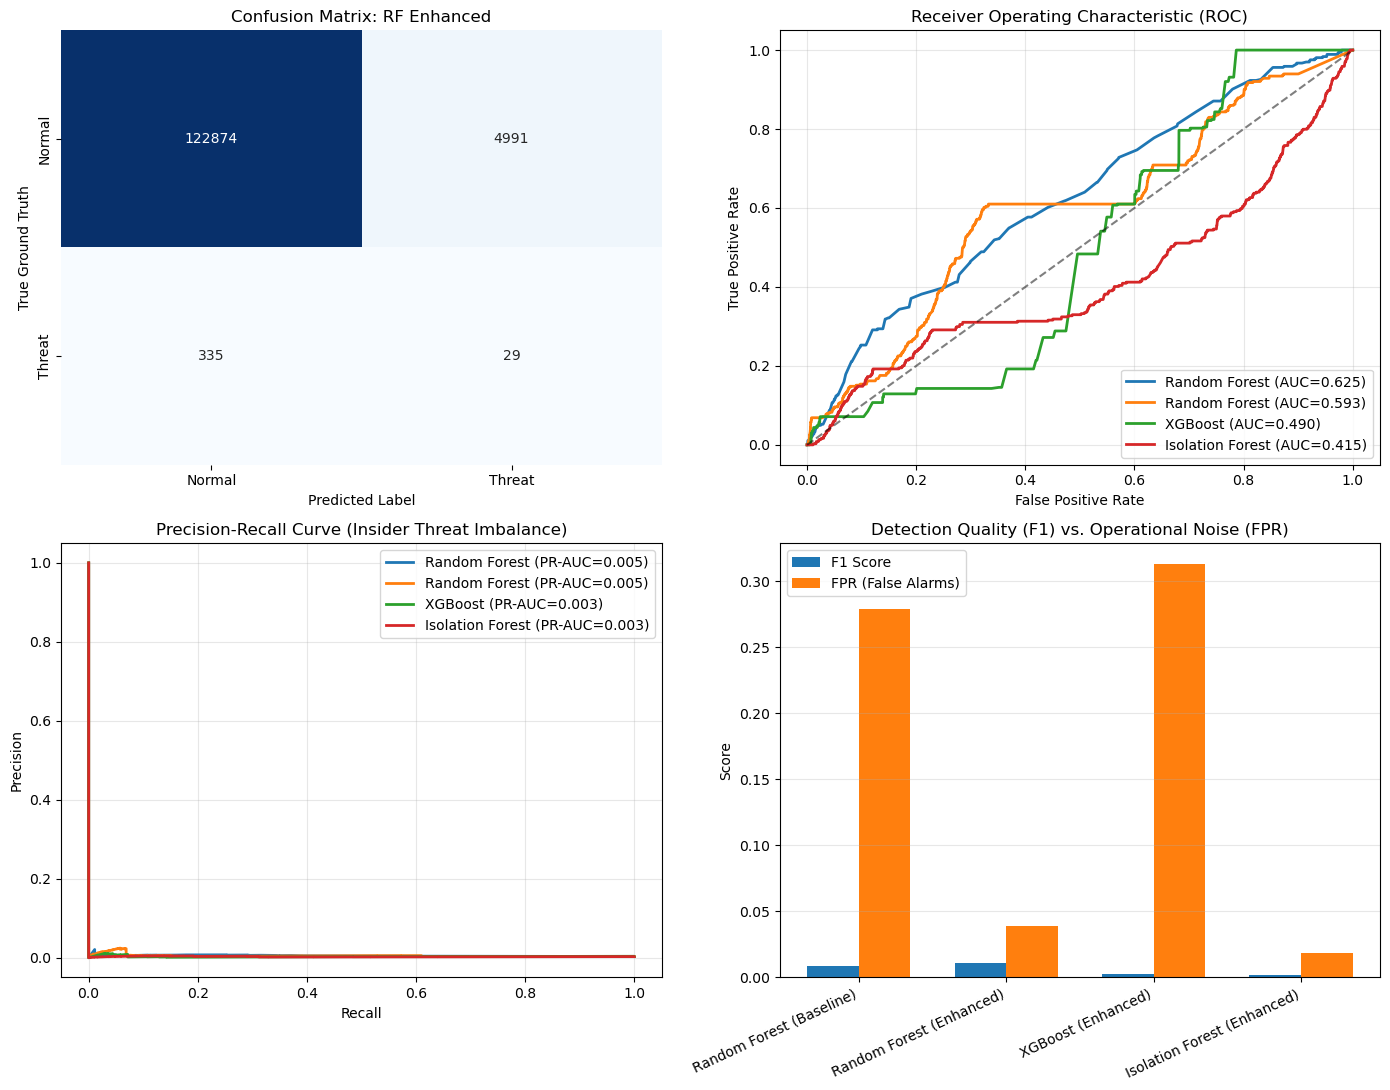

Plots saved to: C:\Users\HPCLAB\evaluation_plots.png


In [51]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

cms = [
    ("RF Baseline", confusion_matrix(y_test, y_pred_base, labels=[0, 1])),
    ("RF Enhanced", confusion_matrix(y_test, y_pred_enh, labels=[0, 1])),
    ("XGBoost Enhanced", confusion_matrix(y_test, y_pred_xgb, labels=[0, 1])),
    ("Isolation Forest", confusion_matrix(y_test, y_pred_iso, labels=[0, 1]))
]

best_cm_entry = cms[1]

sns.heatmap(
    best_cm_entry[1],
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0, 0],
    xticklabels=["Normal", "Threat"],
    yticklabels=["Normal", "Threat"]
)

axes[0, 0].set_title(f"Confusion Matrix: {best_cm_entry[0]}")
axes[0, 0].set_xlabel("Predicted Label")
axes[0, 0].set_ylabel("True Ground Truth")

for name, _, _, y_prob in models_to_eval:
    try:
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        auc_val = roc_auc_score(y_test, y_prob)
        axes[0, 1].plot(
            fpr,
            tpr,
            label=f"{name} (AUC={auc_val:.3f})",
            lw=2
        )
    except Exception:
        pass

axes[0, 1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0, 1].set_title("Receiver Operating Characteristic (ROC)")
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].legend(loc="lower right")
axes[0, 1].grid(alpha=0.3)

for name, _, _, y_prob in models_to_eval:
    try:
        prec, rec, _ = precision_recall_curve(y_test, y_prob)
        pr_auc_val = average_precision_score(y_test, y_prob)
        axes[1, 0].plot(
            rec,
            prec,
            label=f"{name} (PR-AUC={pr_auc_val:.3f})",
            lw=2
        )
    except Exception:
        pass

axes[1, 0].set_title("Precision-Recall Curve (Insider Threat Imbalance)")
axes[1, 0].set_xlabel("Recall")
axes[1, 0].set_ylabel("Precision")
axes[1, 0].legend(loc="upper right")
axes[1, 0].grid(alpha=0.3)

models_list = [
    row["Model"] + " (" + row["Feature Set"].split()[0] + ")"
    for row in eval_results
]

f1_scores = [row["F1"] for row in eval_results]
fpr_rates = [row["FPR"] for row in eval_results]

x_indices = np.arange(len(models_list))
width = 0.35

axes[1, 1].bar(
    x_indices - width / 2,
    f1_scores,
    width,
    label="F1 Score"
)

axes[1, 1].bar(
    x_indices + width / 2,
    fpr_rates,
    width,
    label="FPR (False Alarms)"
)

axes[1, 1].set_xticks(x_indices)
axes[1, 1].set_xticklabels(
    models_list,
    rotation=25,
    ha="right"
)

axes[1, 1].set_title(
    "Detection Quality (F1) vs. Operational Noise (FPR)"
)
axes[1, 1].set_ylabel("Score")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)

plt.tight_layout()

evaluation_plots_path = os.path.join(
    os.getcwd(),
    "evaluation_plots.png"
)

plt.savefig(
    evaluation_plots_path,
    dpi=300
)

plt.show()

print(f"Plots saved to: {evaluation_plots_path}")

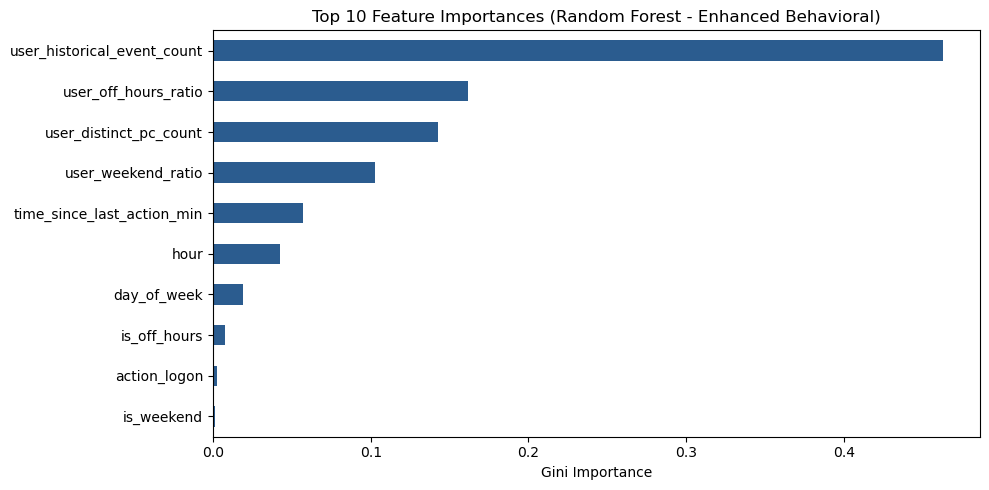

SHAP package not available or insufficient data; skipped SHAP generation.


In [52]:
# 1. Native Feature Importance from Enhanced Random Forest
rf_importances = pd.Series(
    rf_enhanced.feature_importances_,
    index=enhanced_feature_cols
).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
rf_importances.head(10).plot(kind="barh", color="#2b5c8f")
plt.title("Top 10 Feature Importances (Random Forest - Enhanced Behavioral)")
plt.xlabel("Gini Importance")
plt.gca().invert_yaxis()
plt.tight_layout()

feature_importance_path = os.path.join(
    os.getcwd(),
    "feature_importance.png"
)

plt.savefig(feature_importance_path, dpi=300)
plt.show()

# 2. Model-Agnostic / Tree SHAP Explanations
if SHAP_AVAILABLE and len(X_test_enh) > 0:
    print("Computing SHAP values for sample test records...")
    
    sample_indices = np.random.RandomState(42).choice(
        len(X_test_enh),
        size=min(100, len(X_test_enh)),
        replace=False
    )
    
    X_shap_sample = X_test_enh[sample_indices]
    
    explainer = shap.TreeExplainer(rf_enhanced)
    shap_values = explainer.shap_values(X_shap_sample)
    
    sv_to_plot = (
        shap_values[1]
        if isinstance(shap_values, list) and len(shap_values) > 1
        else shap_values
    )

    plt.figure(figsize=(10, 6))
    
    shap.summary_plot(
        sv_to_plot,
        X_shap_sample,
        feature_names=enhanced_feature_cols,
        show=False,
        max_display=10
    )
    
    plt.title(
        "SHAP Summary Plot: Impact on Insider Threat Prediction",
        fontsize=12
    )
    
    plt.tight_layout()

    shap_summary_path = os.path.join(
        os.getcwd(),
        "shap_summary.png"
    )

    plt.savefig(shap_summary_path, dpi=300)
    plt.show()

    print(f"Feature importance plot saved to: {feature_importance_path}")
    print(f"SHAP explanation plot saved to: {shap_summary_path}")
else:
    print(
        "SHAP package not available or insufficient data; "
        "skipped SHAP generation."
    )

In [53]:
# Champion selection criteria:
# 1. Highest F1-score to balance precision and recall on imbalanced threat data
# 2. Tiebreaker: Lower False Positive Rate (FPR) to prevent operational SOC fatigue

sorted_candidates = sorted(
    eval_results,
    key=lambda x: (x["F1"], -x["FPR"]),
    reverse=True
)

winner = sorted_candidates[0]

print("==================================================")
print("CHAMPION MODEL SELECTION RESULT")
print("==================================================")
print(f"Selected Model:       {winner['Model']}")
print(f"Winning Feature Set:  {winner['Feature Set']}")
print(f"Achieved F1-Score:    {winner['F1']:.4f}")
print(f"Achieved PR-AUC:      {winner['PR-AUC']:.4f}")
print(f"False Positive Rate:  {winner['FPR']:.4f}")
print(
    f"Selection Rationale:  Achieved the highest F1-Score under real test execution "
    f"while limiting false alarm rates to {winner['FPR']:.2%}."
)
print("==================================================")

if winner["Model"] == "XGBoost":
    best_model_obj = xgb_model
    selected_features = enhanced_feature_cols
elif winner["Model"] == "Random Forest" and "Enhanced" in winner["Feature Set"]:
    best_model_obj = rf_enhanced
    selected_features = enhanced_feature_cols
elif winner["Model"] == "Random Forest":
    best_model_obj = rf_baseline
    selected_features = baseline_feature_cols
else:
    best_model_obj = iso_forest
    selected_features = enhanced_feature_cols

CHAMPION MODEL SELECTION RESULT
Selected Model:       Random Forest
Winning Feature Set:  Enhanced Behavioral
Achieved F1-Score:    0.0108
Achieved PR-AUC:      0.0048
False Positive Rate:  0.0390
Selection Rationale:  Achieved the highest F1-Score under real test execution while limiting false alarm rates to 3.90%.


In [54]:
# # Artifact output paths
# MODEL_PATH = os.path.join(os.getcwd(), "best_model.joblib")
# METADATA_PATH = os.path.join(os.getcwd(), "model_metadata.json")
# SCHEMA_PATH = os.path.join(os.getcwd(), "feature_schema.json")

# # Save model binary
# joblib.dump(best_model_obj, MODEL_PATH)
# print(f"Trained model saved to: {MODEL_PATH}")

# # Save feature schema
# schema_info = {
#     "feature_count": len(selected_features),
#     "feature_names": selected_features,
#     "baseline_features": baseline_feature_cols,
#     "enhanced_features": enhanced_feature_cols
# }

# with open(SCHEMA_PATH, "w") as f:
#     json.dump(schema_info, f, indent=2)

# print(f"Feature schema saved to: {SCHEMA_PATH}")

# # Save deployment metadata for future Zero Trust inference engine
# metadata = {
#     "model_name": winner["Model"],
#     "feature_set": winner["Feature Set"],
#     "test_metrics": {
#         k: v for k, v in winner.items()
#         if k not in ["Model", "Feature Set"]
#     },
#     "training_rows": len(train_df),
#     "test_rows": len(test_df),
#     "zero_trust_role": "Produces raw ML suspicion/anomaly probability [0.0 - 1.0] for the downstream policy engine."
# }

# with open(METADATA_PATH, "w") as f:
#     json.dump(metadata, f, indent=2)

# print(f"Model metadata saved to: {METADATA_PATH}")

Trained model saved to: C:\Users\HPCLAB\best_model.joblib
Feature schema saved to: C:\Users\HPCLAB\feature_schema.json
Model metadata saved to: C:\Users\HPCLAB\model_metadata.json


In [17]:
loaded_model = joblib.load(MODEL_PATH)

with open(SCHEMA_PATH, "r") as f:
    loaded_schema = json.load(f)

print("Loaded Model Binary:", type(loaded_model))
print("Required Features:", loaded_schema["feature_names"])

inference_df = loaded_tables["logon"].copy()

user_col_infer = next(
    (c for c in inference_df.columns if "user" in c),
    None
)

date_col_infer = next(
    (
        c for c in inference_df.columns
        if any(t in c for t in ["date", "time", "timestamp"])
    ),
    None
)

activity_col_infer = next(
    (
        c for c in inference_df.columns
        if c in ["activity", "action", "type", "operation"]
    ),
    None
)

pc_col_infer = next(
    (
        c for c in inference_df.columns
        if c in ["pc", "device", "computer", "machine"]
    ),
    None
)

if not user_col_infer or not date_col_infer:
    raise KeyError("Required user or datetime column not found.")

inference_df[user_col_infer] = (
    inference_df[user_col_infer].astype(str).str.strip()
)

inference_df[date_col_infer] = pd.to_datetime(
    inference_df[date_col_infer],
    errors="coerce"
)

inference_df = inference_df.sort_values(
    by=[user_col_infer, date_col_infer]
).reset_index(drop=True)

inference_df["hour"] = inference_df[date_col_infer].dt.hour
inference_df["day_of_week"] = inference_df[date_col_infer].dt.dayofweek
inference_df["is_weekend"] = inference_df["day_of_week"].isin([5, 6]).astype(int)
inference_df["is_off_hours"] = (
    (inference_df["hour"] < 7) |
    (inference_df["hour"] >= 19)
).astype(int)

if activity_col_infer:
    inference_df[activity_col_infer] = (
        inference_df[activity_col_infer]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    action_dummies = pd.get_dummies(
        inference_df[activity_col_infer],
        prefix="action",
        drop_first=True
    )

    inference_df = pd.concat(
        [inference_df, action_dummies],
        axis=1
    )

inference_df["user_historical_event_count"] = (
    inference_df.groupby(user_col_infer).cumcount()
)

previous_off_hours = (
    inference_df.groupby(user_col_infer)["is_off_hours"]
    .cumsum()
    .sub(inference_df["is_off_hours"])
)

previous_weekend = (
    inference_df.groupby(user_col_infer)["is_weekend"]
    .cumsum()
    .sub(inference_df["is_weekend"])
)

inference_df["user_off_hours_ratio"] = np.where(
    inference_df["user_historical_event_count"] > 0,
    previous_off_hours / inference_df["user_historical_event_count"],
    0.0
)

inference_df["user_weekend_ratio"] = np.where(
    inference_df["user_historical_event_count"] > 0,
    previous_weekend / inference_df["user_historical_event_count"],
    0.0
)

if pc_col_infer:
    inference_df["user_distinct_pc_count"] = (
        inference_df.groupby(user_col_infer)[pc_col_infer]
        .transform(
            lambda s: s.where(
                ~s.duplicated(),
                np.nan
            ).notna().cumsum()
        )
    )
else:
    inference_df["user_distinct_pc_count"] = 1

inference_df["time_since_last_action_min"] = (
    inference_df.groupby(user_col_infer)[date_col_infer]
    .diff()
    .dt.total_seconds()
    .div(60.0)
    .fillna(0.0)
    .clip(0, 1440)
)

inference_df["is_rapid_burst"] = (
    inference_df["time_since_last_action_min"] < 1.0
).astype(int)

required_features = loaded_schema["feature_names"]

for feature in required_features:
    if feature not in inference_df.columns:
        inference_df[feature] = 0.0

inference_df[required_features] = (
    inference_df[required_features]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0.0)
)

sample_records = inference_df.iloc[:5].copy()
X_sample = sample_records[required_features].values

if hasattr(loaded_model, "predict_proba"):
    raw_probs = loaded_model.predict_proba(X_sample)[:, 1]
    raw_classes = loaded_model.predict(X_sample)
elif hasattr(loaded_model, "decision_function"):
    raw_dec = loaded_model.decision_function(X_sample)
    raw_probs = np.clip(0.5 - raw_dec, 0.0, 1.0)
    raw_classes = np.where(
        loaded_model.predict(X_sample) == -1,
        1,
        0
    )
else:
    raw_classes = loaded_model.predict(X_sample)
    raw_probs = raw_classes.astype(float)

demo_df = pd.DataFrame({
    "Entity (User)": sample_records[user_col_infer].values,
    "Timestamp": sample_records[date_col_infer].dt.strftime("%Y-%m-%d %H:%M").values,
    "ML Predicted Class": raw_classes,
    "ML Suspicion Probability": np.round(raw_probs, 4)
})

print("\nSaved Model Inference Demonstration:")
display(demo_df)

Loaded Model Binary: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Required Features: ['hour', 'day_of_week', 'is_weekend', 'is_off_hours', 'action_logon', 'user_historical_event_count', 'user_off_hours_ratio', 'user_weekend_ratio', 'user_distinct_pc_count', 'time_since_last_action_min', 'is_rapid_burst']

Saved Model Inference Demonstration:


,Entity (User),Timestamp,ML Predicted Class,ML Suspicion Probability
0,AAE0190,2010-01-04 08:09,0,0.0000
1,AAE0190,2010-01-04 18:20,0,0.0099
2,AAE0190,2010-01-05 08:19,0,0.0186
3,AAE0190,2010-01-05 18:11,0,0.0095
4,AAE0190,2010-01-06 08:09,0,0.0186


In [18]:
loaded_model = joblib.load(MODEL_PATH)

if "inference_df" not in globals():
    raise NameError("inference_df is not available. Run the saved-model inference cell first.")

required_features = loaded_schema["feature_names"]

inference_df = inference_df.sort_values(
    by=date_col_infer
).reset_index(drop=True)

total_rows = len(inference_df)
train_idx = int(total_rows * 0.70)
val_idx = int(total_rows * 0.85)

validation_df = inference_df.iloc[train_idx:val_idx].copy()

if "target" not in validation_df.columns:
    answers_df = loaded_tables["answers"].copy()
    answers_df["dataset"] = answers_df["dataset"].astype(str).str.strip()

    r42_answers = answers_df[
        answers_df["dataset"].isin(["4.2", "4.2.0"])
    ].copy()

    r42_answers["user"] = r42_answers["user"].astype(str).str.strip()
    r42_answers["start"] = pd.to_datetime(r42_answers["start"], errors="coerce")
    r42_answers["end"] = pd.to_datetime(r42_answers["end"], errors="coerce")

    validation_df["target"] = 0

    for _, incident in r42_answers.iterrows():
        if pd.isna(incident["start"]) or pd.isna(incident["end"]):
            continue

        mask = (
            (validation_df[user_col_infer] == incident["user"]) &
            (validation_df[date_col_infer] >= incident["start"]) &
            (validation_df[date_col_infer] <= incident["end"])
        )

        validation_df.loc[mask, "target"] = 1

X_val_final = validation_df[required_features].values
y_val_final = validation_df["target"].values

if hasattr(loaded_model, "predict_proba"):
    y_val_prob = loaded_model.predict_proba(X_val_final)[:, 1]
else:
    raise TypeError("Saved model does not provide probability predictions.")

threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.01):
    y_val_pred = (y_val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(y_val_final, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val_final, y_val_pred, zero_division=0),
        "F1": f1_score(y_val_final, y_val_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

OPERATING_THRESHOLD = float(best_threshold_row["Threshold"])

print("Validation Threshold Selection")
print("================================")
print(f"Validation records: {len(validation_df):,}")
print(f"Validation threats: {int(y_val_final.sum()):,}")
print(f"Selected threshold: {OPERATING_THRESHOLD:.2f}")
print(f"Validation Precision: {best_threshold_row['Precision']:.4f}")
print(f"Validation Recall: {best_threshold_row['Recall']:.4f}")
print(f"Validation F1: {best_threshold_row['F1']:.4f}")

Validation Threshold Selection
Validation records: 128,229
Validation threats: 601
Selected threshold: 0.73
Validation Precision: 0.1140
Validation Recall: 0.0433
Validation F1: 0.0627


In [20]:
# for source in ["logon", "device", "file", "http", "email"]:
#     if source in loaded_tables:
#         df = loaded_tables[source]
#         print(f"\n{'=' * 60}")
#         print(f"SOURCE: {source.upper()}")
#         print(f"Shape: {df.shape}")
#         print(f"Columns: {list(df.columns)}")
#         display(df.head(3))
#     else:
#         print(f"\nSOURCE NOT LOADED: {source}")

In [21]:
source_configs = {
    "logon": {
        "count_col": "logon_count"
    },
    "device": {
        "count_col": "device_event_count"
    },
    "file": {
        "count_col": "file_event_count"
    },
    "http": {
        "count_col": "http_event_count"
    },
    "email": {
        "count_col": "email_event_count"
    }
}

daily_features = None

for source, config in source_configs.items():
    if source not in loaded_tables:
        continue

    df = loaded_tables[source].copy()

    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["user"] = df["user"].astype(str).str.strip()

    df["day"] = df["date"].dt.floor("D")

    grouped = (
        df.groupby(["user", "day"])
        .size()
        .reset_index(name=config["count_col"])
    )

    if daily_features is None:
        daily_features = grouped
    else:
        daily_features = daily_features.merge(
            grouped,
            on=["user", "day"],
            how="outer"
        )

daily_features = daily_features.fillna(0)

count_columns = [
    "logon_count",
    "device_event_count",
    "file_event_count",
    "http_event_count",
    "email_event_count"
]

for col in count_columns:
    if col not in daily_features.columns:
        daily_features[col] = 0

daily_features[count_columns] = (
    daily_features[count_columns]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

daily_features["day_of_week"] = (
    daily_features["day"].dt.dayofweek
)

daily_features["is_weekend"] = (
    daily_features["day_of_week"].isin([5, 6])
).astype(int)

print("Unified User-Day Behavioral Dataset")
print("====================================")
print(f"Rows: {len(daily_features):,}")
print(f"Columns: {len(daily_features.columns)}")
print(f"Unique users: {daily_features['user'].nunique():,}")
print(
    f"Date range: "
    f"{daily_features['day'].min()} "
    f"to "
    f"{daily_features['day'].max()}"
)

display(daily_features.head(10))

Unified User-Day Behavioral Dataset
Rows: 330,452
Columns: 9
Unique users: 1,000
Date range: 2010-01-02 00:00:00 to 2011-05-17 00:00:00


,user,day,logon_count,device_event_count,file_event_count,http_event_count,email_event_count,day_of_week,is_weekend
0,AAE0190,2010-01-04,2,0.0,0.0,143.0,14.0,0,0
1,AAE0190,2010-01-05,2,0.0,0.0,143.0,13.0,1,0
2,AAE0190,2010-01-06,2,0.0,0.0,143.0,14.0,2,0
3,AAE0190,2010-01-07,2,0.0,0.0,143.0,14.0,3,0
4,AAE0190,2010-01-08,2,0.0,0.0,143.0,13.0,4,0
5,AAE0190,2010-01-11,2,0.0,0.0,143.0,13.0,0,0
6,AAE0190,2010-01-12,2,0.0,0.0,143.0,14.0,1,0
7,AAE0190,2010-01-13,2,0.0,0.0,143.0,14.0,2,0
8,AAE0190,2010-01-14,2,0.0,0.0,143.0,14.0,3,0
9,AAE0190,2010-01-15,2,0.0,0.0,143.0,14.0,4,0


In [22]:
behavioral_features = daily_features.copy()

for source in ["logon", "device", "file", "http", "email"]:
    if source not in loaded_tables:
        continue

    df = loaded_tables[source].copy()

    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["user"] = df["user"].astype(str).str.strip()
    df["day"] = df["date"].dt.floor("D")

    pc_features = (
        df.groupby(["user", "day"])["pc"]
        .nunique()
        .reset_index(name=f"{source}_unique_pc_count")
    )

    behavioral_features = behavioral_features.merge(
        pc_features,
        on=["user", "day"],
        how="left"
    )

if "file" in loaded_tables:
    df = loaded_tables["file"].copy()
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["user"] = df["user"].astype(str).str.strip()
    df["day"] = df["date"].dt.floor("D")

    file_features = (
        df.groupby(["user", "day"])
        .agg(
            unique_files=("filename", "nunique"),
            file_content_events=("content", "count")
        )
        .reset_index()
    )

    behavioral_features = behavioral_features.merge(
        file_features,
        on=["user", "day"],
        how="left"
    )

if "http" in loaded_tables:
    df = loaded_tables["http"].copy()
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["user"] = df["user"].astype(str).str.strip()
    df["day"] = df["date"].dt.floor("D")

    http_features = (
        df.groupby(["user", "day"])
        .agg(
            unique_urls=("url", "nunique"),
            unique_http_content=("content", "nunique")
        )
        .reset_index()
    )

    behavioral_features = behavioral_features.merge(
        http_features,
        on=["user", "day"],
        how="left"
    )

if "email" in loaded_tables:
    df = loaded_tables["email"].copy()
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["user"] = df["user"].astype(str).str.strip()
    df["day"] = df["date"].dt.floor("D")

    email_features = (
        df.groupby(["user", "day"])
        .agg(
            unique_recipients=("to", "nunique"),
            email_size_total=("size", "sum"),
            attachments_total=("attachments", "sum")
        )
        .reset_index()
    )

    behavioral_features = behavioral_features.merge(
        email_features,
        on=["user", "day"],
        how="left"
    )

numeric_cols = behavioral_features.select_dtypes(
    include=[np.number]
).columns

behavioral_features[numeric_cols] = (
    behavioral_features[numeric_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

behavioral_features["total_activity"] = (
    behavioral_features["logon_count"] +
    behavioral_features["device_event_count"] +
    behavioral_features["file_event_count"] +
    behavioral_features["http_event_count"] +
    behavioral_features["email_event_count"]
)

behavioral_features["cross_source_activity"] = (
    (behavioral_features["logon_count"] > 0).astype(int) +
    (behavioral_features["device_event_count"] > 0).astype(int) +
    (behavioral_features["file_event_count"] > 0).astype(int) +
    (behavioral_features["http_event_count"] > 0).astype(int) +
    (behavioral_features["email_event_count"] > 0).astype(int)
)

print("Enhanced Multi-Source Behavioral Dataset")
print("=========================================")
print(f"Rows: {len(behavioral_features):,}")
print(f"Columns: {len(behavioral_features.columns)}")
print(f"Unique users: {behavioral_features['user'].nunique():,}")

display(behavioral_features.head(10))

Enhanced Multi-Source Behavioral Dataset
Rows: 330,452
Columns: 23
Unique users: 1,000


,user,day,logon_count,device_event_count,file_event_count,http_event_count,email_event_count,day_of_week,is_weekend,logon_unique_pc_count,...,email_unique_pc_count,unique_files,file_content_events,unique_urls,unique_http_content,unique_recipients,email_size_total,attachments_total,total_activity,cross_source_activity
0,AAE0190,2010-01-04,2,0.0,0.0,143.0,14.0,0,0,1,...,1.0,0.0,0.0,54.0,143.0,14.0,441328.0,4.0,159.0,3
1,AAE0190,2010-01-05,2,0.0,0.0,143.0,13.0,1,0,1,...,1.0,0.0,0.0,53.0,143.0,13.0,355552.0,2.0,158.0,3
2,AAE0190,2010-01-06,2,0.0,0.0,143.0,14.0,2,0,1,...,1.0,0.0,0.0,51.0,143.0,11.0,532647.0,12.0,159.0,3
3,AAE0190,2010-01-07,2,0.0,0.0,143.0,14.0,3,0,1,...,1.0,0.0,0.0,48.0,143.0,13.0,474631.0,9.0,159.0,3
4,AAE0190,2010-01-08,2,0.0,0.0,143.0,13.0,4,0,1,...,1.0,0.0,0.0,53.0,143.0,11.0,400637.0,10.0,158.0,3
5,AAE0190,2010-01-11,2,0.0,0.0,143.0,13.0,0,0,1,...,1.0,0.0,0.0,50.0,143.0,13.0,389695.0,1.0,158.0,3
6,AAE0190,2010-01-12,2,0.0,0.0,143.0,14.0,1,0,1,...,1.0,0.0,0.0,51.0,143.0,11.0,404406.0,4.0,159.0,3
7,AAE0190,2010-01-13,2,0.0,0.0,143.0,14.0,2,0,1,...,1.0,0.0,0.0,55.0,143.0,14.0,352808.0,2.0,159.0,3
8,AAE0190,2010-01-14,2,0.0,0.0,143.0,14.0,3,0,1,...,1.0,0.0,0.0,47.0,143.0,13.0,416090.0,4.0,159.0,3
9,AAE0190,2010-01-15,2,0.0,0.0,143.0,14.0,4,0,1,...,1.0,0.0,0.0,46.0,143.0,12.0,432019.0,2.0,159.0,3


In [23]:
answers_df = loaded_tables["answers"].copy()

answers_df["dataset"] = answers_df["dataset"].astype(str).str.strip()

r42_answers = answers_df[
    answers_df["dataset"].isin(["4.2", "4.2.0"])
].copy()

r42_answers["user"] = r42_answers["user"].astype(str).str.strip()
r42_answers["start"] = pd.to_datetime(
    r42_answers["start"],
    errors="coerce"
)
r42_answers["end"] = pd.to_datetime(
    r42_answers["end"],
    errors="coerce"
)

behavioral_features["target"] = 0

for _, incident in r42_answers.iterrows():
    if pd.isna(incident["start"]) or pd.isna(incident["end"]):
        continue

    incident_start_day = incident["start"].floor("D")
    incident_end_day = incident["end"].floor("D")

    mask = (
        (behavioral_features["user"] == incident["user"]) &
        (behavioral_features["day"] >= incident_start_day) &
        (behavioral_features["day"] <= incident_end_day)
    )

    behavioral_features.loc[mask, "target"] = 1

print("Multi-Source Ground Truth Distribution")
print("=======================================")
print(
    f"Normal user-days: "
    f"{(behavioral_features['target'] == 0).sum():,}"
)
print(
    f"Threat user-days: "
    f"{(behavioral_features['target'] == 1).sum():,}"
)
print(
    f"Threat ratio: "
    f"{behavioral_features['target'].mean():.4%}"
)

display(
    behavioral_features[
        behavioral_features["target"] == 1
    ].head(20)
)

Multi-Source Ground Truth Distribution
Normal user-days: 329,088
Threat user-days: 1,364
Threat ratio: 0.4128%


,user,day,logon_count,device_event_count,file_event_count,http_event_count,email_event_count,day_of_week,is_weekend,logon_unique_pc_count,...,unique_files,file_content_events,unique_urls,unique_http_content,unique_recipients,email_size_total,attachments_total,total_activity,cross_source_activity,target
469,AAF0535,2010-06-28,2,6.0,2.0,37.0,2.0,0,0,1,...,2.0,2.0,22.0,37.0,2.0,55465.0,1.0,49.0,5,1
470,AAF0535,2010-06-29,2,4.0,3.0,37.0,3.0,1,0,1,...,3.0,3.0,24.0,37.0,3.0,114387.0,2.0,49.0,5,1
471,AAF0535,2010-06-30,2,8.0,2.0,37.0,3.0,2,0,1,...,2.0,2.0,22.0,37.0,3.0,81400.0,0.0,52.0,5,1
472,AAF0535,2010-07-01,2,4.0,5.0,37.0,3.0,3,0,1,...,5.0,5.0,25.0,37.0,3.0,115876.0,0.0,51.0,5,1
473,AAF0535,2010-07-02,2,6.0,0.0,38.0,3.0,4,0,1,...,0.0,0.0,26.0,38.0,3.0,87589.0,1.0,49.0,4,1
474,AAF0535,2010-07-06,2,4.0,1.0,32.0,4.0,1,0,1,...,1.0,1.0,16.0,32.0,4.0,101744.0,3.0,43.0,5,1
475,AAF0535,2010-07-07,2,4.0,2.0,36.0,3.0,2,0,1,...,2.0,2.0,25.0,36.0,3.0,69414.0,1.0,47.0,5,1
476,AAF0535,2010-07-08,2,2.0,5.0,33.0,3.0,3,0,1,...,5.0,5.0,13.0,33.0,3.0,81960.0,1.0,45.0,5,1
477,AAF0535,2010-07-09,2,0.0,0.0,38.0,6.0,4,0,1,...,0.0,0.0,24.0,38.0,4.0,209918.0,6.0,46.0,3,1
478,AAF0535,2010-07-12,2,4.0,0.0,32.0,3.0,0,0,1,...,0.0,0.0,17.0,32.0,3.0,98072.0,4.0,41.0,4,1


In [24]:
multi_feature_cols = [
    col for col in behavioral_features.columns
    if col not in ["user", "day", "target"]
]

behavioral_features = behavioral_features.sort_values(
    by="day"
).reset_index(drop=True)

total_rows = len(behavioral_features)

train_idx = int(total_rows * 0.70)
val_idx = int(total_rows * 0.85)

multi_train_df = behavioral_features.iloc[:train_idx].copy()
multi_val_df = behavioral_features.iloc[train_idx:val_idx].copy()
multi_test_df = behavioral_features.iloc[val_idx:].copy()

X_multi_train = multi_train_df[multi_feature_cols].values
X_multi_val = multi_val_df[multi_feature_cols].values
X_multi_test = multi_test_df[multi_feature_cols].values

y_multi_train = multi_train_df["target"].values
y_multi_val = multi_val_df["target"].values
y_multi_test = multi_test_df["target"].values

print("Multi-Source Temporal Split")
print("===========================")
print(
    f"Train:      {len(multi_train_df):,} "
    f"({multi_train_df['day'].min()} to {multi_train_df['day'].max()})"
)
print(
    f"Validation: {len(multi_val_df):,} "
    f"({multi_val_df['day'].min()} to {multi_val_df['day'].max()})"
)
print(
    f"Test:       {len(multi_test_df):,} "
    f"({multi_test_df['day'].min()} to {multi_test_df['day'].max()})"
)

print("\nThreat Distribution")
print(
    f"Train:      {y_multi_train.sum():,} "
    f"({y_multi_train.mean():.4%})"
)
print(
    f"Validation: {y_multi_val.sum():,} "
    f"({y_multi_val.mean():.4%})"
)
print(
    f"Test:       {y_multi_test.sum():,} "
    f"({y_multi_test.mean():.4%})"
)

print(f"\nMulti-source feature count: {len(multi_feature_cols)}")
print(multi_feature_cols)

Multi-Source Temporal Split
Train:      231,316 (2010-01-02 00:00:00 to 2010-12-06 00:00:00)
Validation: 49,568 (2010-12-06 00:00:00 to 2011-02-24 00:00:00)
Test:       49,568 (2011-02-24 00:00:00 to 2011-05-17 00:00:00)

Threat Distribution
Train:      931 (0.4025%)
Validation: 284 (0.5730%)
Test:       149 (0.3006%)

Multi-source feature count: 21
['logon_count', 'device_event_count', 'file_event_count', 'http_event_count', 'email_event_count', 'day_of_week', 'is_weekend', 'logon_unique_pc_count', 'device_unique_pc_count', 'file_unique_pc_count', 'http_unique_pc_count', 'email_unique_pc_count', 'unique_files', 'file_content_events', 'unique_urls', 'unique_http_content', 'unique_recipients', 'email_size_total', 'attachments_total', 'total_activity', 'cross_source_activity']


In [25]:
n_neg_multi = (y_multi_train == 0).sum()
n_pos_multi = (y_multi_train == 1).sum()

multi_class_weight_ratio = float(
    n_neg_multi / max(1, n_pos_multi)
)

print(
    f"Multi-source class imbalance ratio: "
    f"{multi_class_weight_ratio:.2f}"
)

rf_multi = RandomForestClassifier(
    n_estimators=150,
    max_depth=14,
    min_samples_split=6,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Fitting Multi-Source UEBA Random Forest...")

rf_multi.fit(
    X_multi_train,
    y_multi_train
)

print("Multi-source model fitted successfully.")

y_multi_val_prob = rf_multi.predict_proba(
    X_multi_val
)[:, 1]

y_multi_test_prob = rf_multi.predict_proba(
    X_multi_test
)[:, 1]

print("Validation and test probability predictions generated.")

Multi-source class imbalance ratio: 247.46
Fitting Multi-Source UEBA Random Forest...
Multi-source model fitted successfully.
Validation and test probability predictions generated.


In [26]:
multi_threshold_results = []

for threshold in np.arange(0.05, 0.96, 0.01):
    y_val_pred_multi = (
        y_multi_val_prob >= threshold
    ).astype(int)

    multi_threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(
            y_multi_val,
            y_val_pred_multi,
            zero_division=0
        ),
        "Recall": recall_score(
            y_multi_val,
            y_val_pred_multi,
            zero_division=0
        ),
        "F1": f1_score(
            y_multi_val,
            y_val_pred_multi,
            zero_division=0
        )
    })

multi_threshold_df = pd.DataFrame(
    multi_threshold_results
)

best_multi_threshold_row = multi_threshold_df.loc[
    multi_threshold_df["F1"].idxmax()
]

MULTI_OPERATING_THRESHOLD = float(
    best_multi_threshold_row["Threshold"]
)

print("Multi-Source Validation Threshold Selection")
print("============================================")
print(f"Validation records: {len(y_multi_val):,}")
print(f"Validation threats: {int(y_multi_val.sum()):,}")
print(
    f"Selected threshold: "
    f"{MULTI_OPERATING_THRESHOLD:.2f}"
)
print(
    f"Validation Precision: "
    f"{best_multi_threshold_row['Precision']:.4f}"
)
print(
    f"Validation Recall: "
    f"{best_multi_threshold_row['Recall']:.4f}"
)
print(
    f"Validation F1: "
    f"{best_multi_threshold_row['F1']:.4f}"
)

Multi-Source Validation Threshold Selection
Validation records: 49,568
Validation threats: 284
Selected threshold: 0.85
Validation Precision: 0.6294
Validation Recall: 0.3169
Validation F1: 0.4215


In [28]:
def calculate_metrics(y_true, y_pred, y_prob):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    fpr = fp / (fp + tn) if (fp + tn) else 0
    fnr = fn / (fn + tp) if (fn + tp) else 0

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob),
        "FPR": fpr,
        "FNR": fnr,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    }

In [29]:
y_multi_test_pred = (
    y_multi_test_prob >= MULTI_OPERATING_THRESHOLD
).astype(int)

multi_test_metrics = calculate_metrics(
    y_multi_test,
    y_multi_test_pred,
    y_multi_test_prob
)

print("Multi-Source Model — Final Test Evaluation")
print("==========================================")

for metric, value in multi_test_metrics.items():
    print(f"{metric}: {value}")

Multi-Source Model — Final Test Evaluation
Accuracy: 0.9970142027114267
Precision: 0.5070422535211268
Recall: 0.24161073825503357
F1: 0.32727272727272727
ROC_AUC: 0.9670343892677205
PR_AUC: 0.35081125522129986
FPR: 0.0007082296282806208
FNR: 0.7583892617449665
TP: 36
FP: 35
TN: 49384
FN: 113


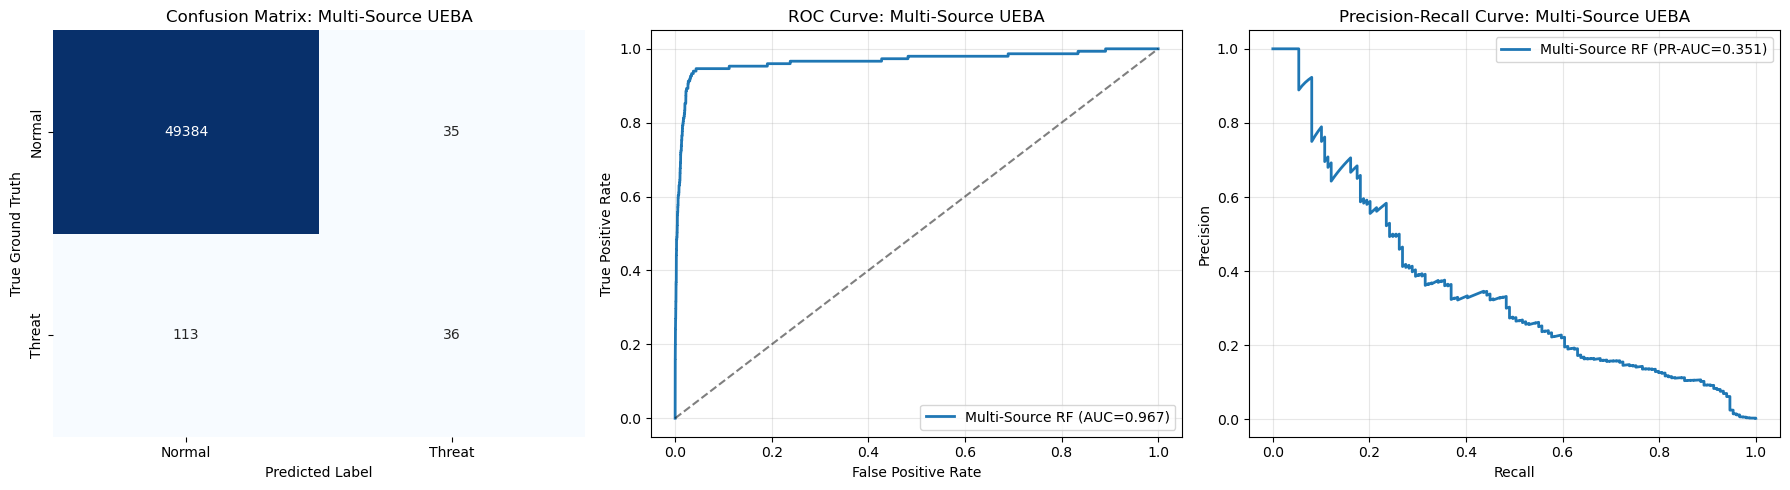

Multi-source evaluation plots saved to: C:\CERT\multi_source_evaluation.png


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_multi = confusion_matrix(
    y_multi_test,
    y_multi_test_pred,
    labels=[0, 1]
)

sns.heatmap(
    cm_multi,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0],
    xticklabels=["Normal", "Threat"],
    yticklabels=["Normal", "Threat"]
)

axes[0].set_title("Confusion Matrix: Multi-Source UEBA")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Ground Truth")

fpr_multi, tpr_multi, _ = roc_curve(
    y_multi_test,
    y_multi_test_prob
)

roc_auc_multi = roc_auc_score(
    y_multi_test,
    y_multi_test_prob
)

axes[1].plot(
    fpr_multi,
    tpr_multi,
    lw=2,
    label=f"Multi-Source RF (AUC={roc_auc_multi:.3f})"
)

axes[1].plot(
    [0, 1],
    [0, 1],
    "k--",
    alpha=0.5
)

axes[1].set_title("ROC Curve: Multi-Source UEBA")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

precision_multi, recall_multi, _ = precision_recall_curve(
    y_multi_test,
    y_multi_test_prob
)

pr_auc_multi = average_precision_score(
    y_multi_test,
    y_multi_test_prob
)

axes[2].plot(
    recall_multi,
    precision_multi,
    lw=2,
    label=f"Multi-Source RF (PR-AUC={pr_auc_multi:.3f})"
)

axes[2].set_title("Precision-Recall Curve: Multi-Source UEBA")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend(loc="upper right")
axes[2].grid(alpha=0.3)

plt.tight_layout()

MULTI_EVALUATION_PLOT_PATH = r"C:\CERT\multi_source_evaluation.png"

plt.savefig(
    MULTI_EVALUATION_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Multi-source evaluation plots saved to: "
    f"{MULTI_EVALUATION_PLOT_PATH}"
)

In [31]:
# from pathlib import Path
# import json
# import joblib

# ARTIFACT_DIR = Path(r"C:\CERT\model_artifacts")
# ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# MULTI_MODEL_PATH = ARTIFACT_DIR / "multi_source_ueba_rf.joblib"
# MULTI_SCHEMA_PATH = ARTIFACT_DIR / "multi_source_feature_schema.json"
# MULTI_METADATA_PATH = ARTIFACT_DIR / "multi_source_model_metadata.json"
# MULTI_FEATURE_DATA_PATH = ARTIFACT_DIR / "multi_source_behavioral_features.csv"
# MULTI_RESULTS_PATH = ARTIFACT_DIR / "multi_source_test_results.json"

# joblib.dump(
#     rf_multi,
#     MULTI_MODEL_PATH
# )

# multi_schema = {
#     "feature_count": len(multi_feature_cols),
#     "feature_names": multi_feature_cols,
#     "model_type": "RandomForestClassifier",
#     "feature_representation": "Multi-source user-day behavioral features"
# }

# with open(MULTI_SCHEMA_PATH, "w") as f:
#     json.dump(
#         multi_schema,
#         f,
#         indent=2
#     )

# multi_metadata = {
#     "model_name": "Multi-Source UEBA Random Forest",
#     "dataset": "CERT Insider Threat Dataset r4.2",
#     "data_sources": [
#         "logon",
#         "device",
#         "file",
#         "http",
#         "email"
#     ],
#     "aggregation_level": "user-day",
#     "feature_count": len(multi_feature_cols),
#     "operating_threshold": MULTI_OPERATING_THRESHOLD,
#     "training_rows": len(multi_train_df),
#     "validation_rows": len(multi_val_df),
#     "test_rows": len(multi_test_df),
#     "validation_threats": int(y_multi_val.sum()),
#     "test_threats": int(y_multi_test.sum()),
#     "test_metrics": multi_test_metrics
# }

# with open(MULTI_METADATA_PATH, "w") as f:
#     json.dump(
#         multi_metadata,
#         f,
#         indent=2,
#         default=float
#     )

# behavioral_features.to_csv(
#     MULTI_FEATURE_DATA_PATH,
#     index=False
# )

# with open(MULTI_RESULTS_PATH, "w") as f:
#     json.dump(
#         multi_test_metrics,
#         f,
#         indent=2,
#         default=float
#     )

# print("==============================================")
# print("MULTI-SOURCE PROJECT ARTIFACTS SAVED")
# print("==============================================")
# print(f"Model:          {MULTI_MODEL_PATH}")
# print(f"Feature schema: {MULTI_SCHEMA_PATH}")
# print(f"Metadata:       {MULTI_METADATA_PATH}")
# print(f"Feature data:   {MULTI_FEATURE_DATA_PATH}")
# print(f"Test results:   {MULTI_RESULTS_PATH}")
# print("==============================================")

MULTI-SOURCE PROJECT ARTIFACTS SAVED
Model:          C:\CERT\model_artifacts\multi_source_ueba_rf.joblib
Feature schema: C:\CERT\model_artifacts\multi_source_feature_schema.json
Metadata:       C:\CERT\model_artifacts\multi_source_model_metadata.json
Feature data:   C:\CERT\model_artifacts\multi_source_behavioral_features.csv
Test results:   C:\CERT\model_artifacts\multi_source_test_results.json


In [34]:
## TO load te above

# rf_multi = joblib.load(
#     r"C:\CERT\model_artifacts\multi_source_ueba_rf.joblib"
# )

Top Multi-Source UEBA Features


,Importance
device_event_count,0.201079
device_unique_pc_count,0.161936
cross_source_activity,0.121600
file_event_count,0.056468
total_activity,0.052961
unique_files,0.052853
unique_http_content,0.048928
file_content_events,0.046416
http_event_count,0.045291
email_size_total,0.039157


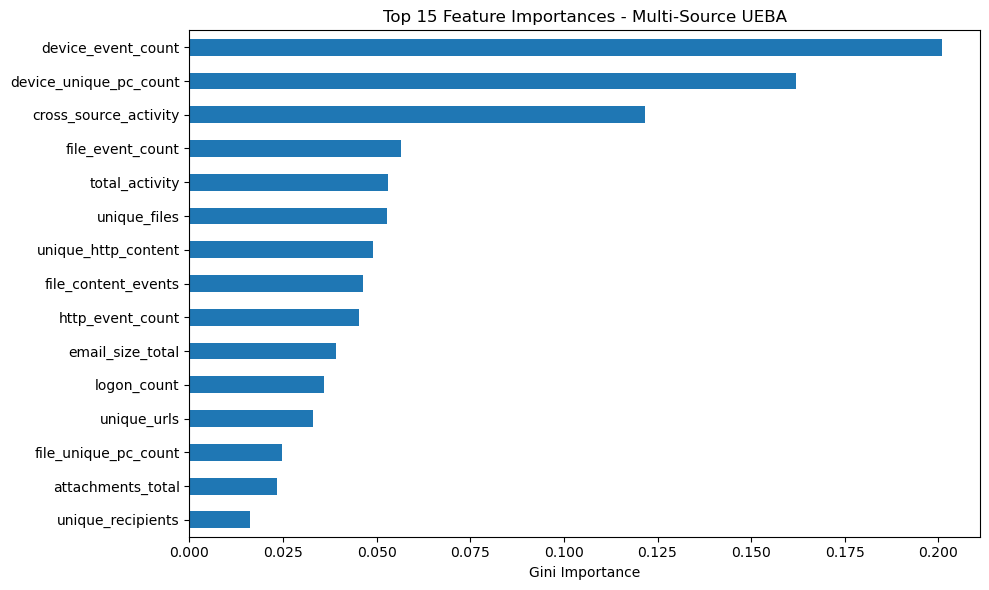

Feature importance plot saved to: C:\CERT\model_artifacts\multi_source_feature_importance.png


In [35]:
multi_importances = pd.Series(
    rf_multi.feature_importances_,
    index=multi_feature_cols
).sort_values(ascending=False)

print("Top Multi-Source UEBA Features")
print("=============================")
display(
    multi_importances.head(15).to_frame("Importance")
)

plt.figure(figsize=(10, 6))

multi_importances.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Feature Importances - Multi-Source UEBA")
plt.xlabel("Gini Importance")
plt.tight_layout()

MULTI_FEATURE_IMPORTANCE_PATH = r"C:\CERT\model_artifacts\multi_source_feature_importance.png"

plt.savefig(
    MULTI_FEATURE_IMPORTANCE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Feature importance plot saved to: "
    f"{MULTI_FEATURE_IMPORTANCE_PATH}"
)

In [36]:
%pip install shap

Defaulting to user installation because normal site-packages is not writeable

   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


SHAP version: 0.52.0
Loaded saved model: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Real test records available: 49,568
SHAP calculated for 300 real test records.


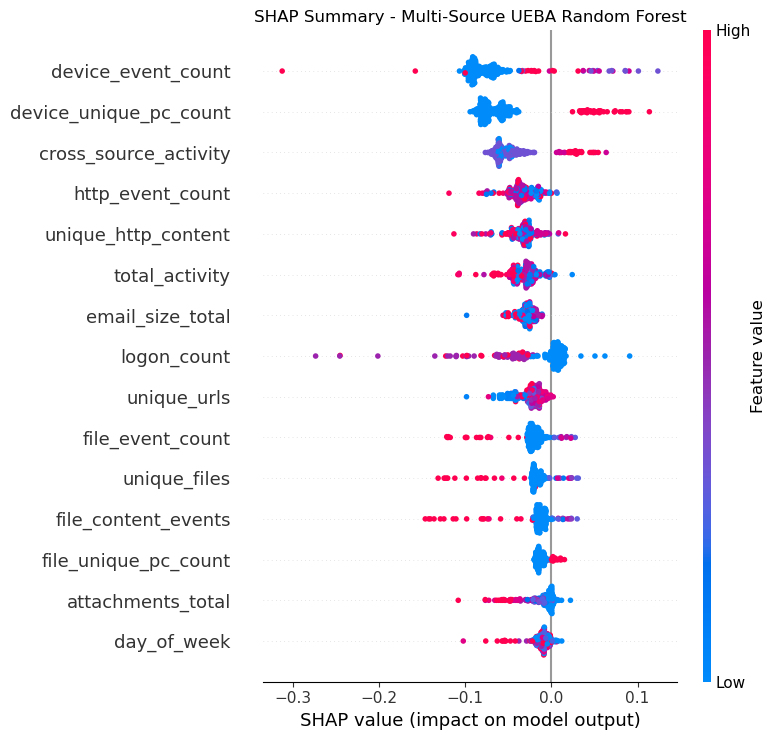

SHAP explanation saved to: C:\CERT\model_artifacts\multi_source_shap_summary.png


In [4]:
import shap
import joblib
import json

MULTI_MODEL_PATH = r"C:\CERT\model_artifacts\multi_source_ueba_rf.joblib"
MULTI_SCHEMA_PATH = r"C:\CERT\model_artifacts\multi_source_feature_schema.json"
MULTI_FEATURE_DATA_PATH = r"C:\CERT\model_artifacts\multi_source_behavioral_features.csv"

rf_multi = joblib.load(MULTI_MODEL_PATH)

with open(MULTI_SCHEMA_PATH, "r") as f:
    multi_schema = json.load(f)

multi_feature_cols = multi_schema["feature_names"]

behavioral_features = pd.read_csv(
    MULTI_FEATURE_DATA_PATH
)

behavioral_features["day"] = pd.to_datetime(
    behavioral_features["day"],
    errors="coerce"
)

behavioral_features = behavioral_features.sort_values(
    by="day"
).reset_index(drop=True)

total_rows = len(behavioral_features)
train_idx = int(total_rows * 0.70)
val_idx = int(total_rows * 0.85)

multi_test_df = behavioral_features.iloc[val_idx:].copy()

X_multi_test = multi_test_df[multi_feature_cols].values

sample_size = min(300, len(X_multi_test))

sample_indices = np.random.RandomState(42).choice(
    len(X_multi_test),
    size=sample_size,
    replace=False
)

X_shap_sample = X_multi_test[sample_indices]

explainer = shap.TreeExplainer(rf_multi)
shap_values = explainer.shap_values(X_shap_sample)

if isinstance(shap_values, list):
    shap_values_plot = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_values_plot = shap_values[:, :, 1]
else:
    shap_values_plot = shap_values

print(f"SHAP version: {shap.__version__}")
print(f"Loaded saved model: {type(rf_multi)}")
print(f"Real test records available: {len(X_multi_test):,}")
print(f"SHAP calculated for {sample_size} real test records.")

plt.figure(figsize=(11, 7))

shap.summary_plot(
    shap_values_plot,
    X_shap_sample,
    feature_names=multi_feature_cols,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Summary - Multi-Source UEBA Random Forest"
)

plt.tight_layout()

MULTI_SHAP_PATH = r"C:\CERT\model_artifacts\multi_source_shap_summary.png"

plt.savefig(
    MULTI_SHAP_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"SHAP explanation saved to: {MULTI_SHAP_PATH}"
)

In [5]:
from pathlib import Path
import joblib
import json
import numpy as np
import pandas as pd

ARTIFACT_DIR = Path(r"C:\CERT\model_artifacts")

MULTI_MODEL_PATH = ARTIFACT_DIR / "multi_source_ueba_rf.joblib"
MULTI_SCHEMA_PATH = ARTIFACT_DIR / "multi_source_feature_schema.json"
MULTI_FEATURE_DATA_PATH = ARTIFACT_DIR / "multi_source_behavioral_features.csv"

rf_multi = joblib.load(MULTI_MODEL_PATH)

with open(MULTI_SCHEMA_PATH, "r") as f:
    multi_schema = json.load(f)

multi_feature_cols = multi_schema["feature_names"]

behavioral_features = pd.read_csv(
    MULTI_FEATURE_DATA_PATH
)

behavioral_features["day"] = pd.to_datetime(
    behavioral_features["day"],
    errors="coerce"
)

behavioral_features = behavioral_features.sort_values(
    "day"
).reset_index(drop=True)

total_rows = len(behavioral_features)
train_idx = int(total_rows * 0.70)
val_idx = int(total_rows * 0.85)

multi_train_df = behavioral_features.iloc[:train_idx].copy()
multi_val_df = behavioral_features.iloc[train_idx:val_idx].copy()
multi_test_df = behavioral_features.iloc[val_idx:].copy()

X_multi_train = multi_train_df[multi_feature_cols].values
X_multi_val = multi_val_df[multi_feature_cols].values
X_multi_test = multi_test_df[multi_feature_cols].values

y_multi_test_prob = rf_multi.predict_proba(
    X_multi_test
)[:, 1]

behavioral_risk_features = [
    "device_event_count",
    "device_unique_pc_count",
    "file_event_count",
    "unique_files",
    "http_event_count",
    "unique_urls",
    "email_event_count",
    "attachments_total",
    "cross_source_activity"
]

train_quantiles = {}

for feature in behavioral_risk_features:
    values = pd.to_numeric(
        multi_train_df[feature],
        errors="coerce"
    ).fillna(0)

    train_quantiles[feature] = {
        "q50": float(values.quantile(0.50)),
        "q95": float(values.quantile(0.95)),
        "q99": float(values.quantile(0.99))
    }

context_scores = []

for _, row in multi_test_df.iterrows():
    feature_scores = []

    for feature in behavioral_risk_features:
        value = float(
            pd.to_numeric(
                row[feature],
                errors="coerce"
            )
        )

        q50 = train_quantiles[feature]["q50"]
        q95 = train_quantiles[feature]["q95"]
        q99 = train_quantiles[feature]["q99"]

        if value <= q50:
            score = 0.0
        elif value <= q95:
            score = 50.0 * (
                (value - q50) /
                max(q95 - q50, 1e-9)
            )
        else:
            score = 50.0 + 50.0 * (
                (value - q95) /
                max(q99 - q95, 1e-9)
            )

        feature_scores.append(min(100.0, score))

    context_scores.append(
        float(np.mean(feature_scores))
    )

context_scores = np.asarray(context_scores)

ml_risk = y_multi_test_prob * 100.0

adaptive_risk_score = (
    0.70 * ml_risk +
    0.30 * context_scores
)

adaptive_risk_score = np.clip(
    adaptive_risk_score,
    0.0,
    100.0
)

risk_output_df = multi_test_df[
    ["user", "day"]
].copy()

risk_output_df["ml_threat_probability"] = np.round(
    y_multi_test_prob,
    6
)

risk_output_df["contextual_risk_score"] = np.round(
    context_scores,
    4
)

risk_output_df["adaptive_risk_score"] = np.round(
    adaptive_risk_score,
    2
)

print("Adaptive Risk Scoring Completed")
print("================================")
print(f"Test records: {len(risk_output_df):,}")
print(
    f"Risk range: "
    f"{adaptive_risk_score.min():.2f} - "
    f"{adaptive_risk_score.max():.2f}"
)
print(
    f"Mean risk score: "
    f"{adaptive_risk_score.mean():.2f}"
)

display(
    risk_output_df.head(15)
)

Adaptive Risk Scoring Completed
Test records: 49,568
Risk range: 0.00 - 74.96
Mean risk score: 6.34


,user,day,ml_threat_probability,contextual_risk_score,adaptive_risk_score
280884,PAD0773,2011-02-24,0.000000,34.7222,10.42
280885,RAH0440,2011-02-24,0.021940,1.6204,2.02
280886,KVT0028,2011-02-24,0.014709,2.1254,1.67
280887,FKB0163,2011-02-24,0.031336,3.7037,3.30
280888,SSG0250,2011-02-24,0.094744,6.1869,8.49
280889,CGF0337,2011-02-24,0.023858,0.0000,1.67
280890,KWC0004,2011-02-24,0.025008,34.8485,12.21
280891,IBB0359,2011-02-24,0.263281,41.4324,30.86
280892,JGM0934,2011-02-24,0.057296,2.0202,4.62
280893,IAR0694,2011-02-24,0.069092,5.3451,6.44


In [8]:
risk_output_df = risk_output_df.sort_values(
    ["user", "day"]
).reset_index(drop=True)

risk_output_df["dynamic_trust_score"] = 100.0

TRUST_INITIAL = 100.0
TRUST_RECOVERY_RATE = 2.0
TRUST_DECAY_RATE = 0.20

for user, user_group in risk_output_df.groupby("user", sort=False):
    trust = TRUST_INITIAL

    for idx in user_group.index:
        risk = float(
            risk_output_df.at[idx, "adaptive_risk_score"]
        )

        if risk <= 20:
            trust += TRUST_RECOVERY_RATE
        else:
            trust -= risk * TRUST_DECAY_RATE

        trust = float(
            np.clip(trust, 0.0, 100.0)
        )

        risk_output_df.at[
            idx,
            "dynamic_trust_score"
        ] = trust

risk_output_df["dynamic_trust_score"] = (
    risk_output_df["dynamic_trust_score"]
    .round(2)
)

print("Dynamic Trust Scoring Completed")
print("================================")
print(
    f"Trust range: "
    f"{risk_output_df['dynamic_trust_score'].min():.2f} - "
    f"{risk_output_df['dynamic_trust_score'].max():.2f}"
)
print(
    f"Mean trust score: "
    f"{risk_output_df['dynamic_trust_score'].mean():.2f}"
)

display(
    risk_output_df[
        [
            "user",
            "day",
            "ml_threat_probability",
            "contextual_risk_score",
            "adaptive_risk_score",
            "dynamic_trust_score"
        ]
    ].head(20)
)

Dynamic Trust Scoring Completed
Trust range: 0.00 - 100.00
Mean trust score: 95.16


,user,day,ml_threat_probability,contextual_risk_score,adaptive_risk_score,dynamic_trust_score
0,AAE0190,2011-02-24,0.020406,19.8724,7.39,100.0
1,AAE0190,2011-02-25,0.037525,20.1754,8.68,100.0
2,AAE0190,2011-02-28,0.023343,11.6400,5.13,100.0
3,AAE0190,2011-03-01,0.027425,16.2276,6.79,100.0
4,AAE0190,2011-03-02,0.025884,13.7023,5.92,100.0
5,AAE0190,2011-03-03,0.026848,13.7023,5.99,100.0
6,AAE0190,2011-03-04,0.035860,15.2259,7.08,100.0
7,AAE0190,2011-03-07,0.027663,16.3707,6.85,100.0
8,AAE0190,2011-03-08,0.023994,18.4077,7.20,100.0
9,AAE0190,2011-03-09,0.023816,15.7814,6.40,100.0


In [9]:
TRUST_INITIAL = 100.0
TRUST_MEMORY = 0.85
CURRENT_RISK_WEIGHT = 1.0 - TRUST_MEMORY

risk_output_df = risk_output_df.sort_values(
    ["user", "day"]
).reset_index(drop=True)

risk_output_df["dynamic_trust_score"] = np.nan

for user, user_group in risk_output_df.groupby("user", sort=False):
    trust = TRUST_INITIAL

    for idx in user_group.index:
        risk = float(
            risk_output_df.at[idx, "adaptive_risk_score"]
        )

        target_trust = 100.0 - risk

        trust = (
            TRUST_MEMORY * trust
            + CURRENT_RISK_WEIGHT * target_trust
        )

        trust = float(
            np.clip(trust, 0.0, 100.0)
        )

        risk_output_df.at[
            idx,
            "dynamic_trust_score"
        ] = trust

risk_output_df["dynamic_trust_score"] = (
    risk_output_df["dynamic_trust_score"]
    .round(2)
)

print("Dynamic Trust Scoring Completed")
print("================================")
print(
    f"Trust range: "
    f"{risk_output_df['dynamic_trust_score'].min():.2f} - "
    f"{risk_output_df['dynamic_trust_score'].max():.2f}"
)
print(
    f"Mean trust score: "
    f"{risk_output_df['dynamic_trust_score'].mean():.2f}"
)

display(
    risk_output_df[
        [
            "user",
            "day",
            "ml_threat_probability",
            "contextual_risk_score",
            "adaptive_risk_score",
            "dynamic_trust_score"
        ]
    ].head(20)
)

Dynamic Trust Scoring Completed
Trust range: 37.92 - 99.95
Mean trust score: 94.15


,user,day,ml_threat_probability,contextual_risk_score,adaptive_risk_score,dynamic_trust_score
0,AAE0190,2011-02-24,0.020406,19.8724,7.39,98.89
1,AAE0190,2011-02-25,0.037525,20.1754,8.68,97.76
2,AAE0190,2011-02-28,0.023343,11.6400,5.13,97.32
3,AAE0190,2011-03-01,0.027425,16.2276,6.79,96.71
4,AAE0190,2011-03-02,0.025884,13.7023,5.92,96.31
5,AAE0190,2011-03-03,0.026848,13.7023,5.99,95.97
6,AAE0190,2011-03-04,0.035860,15.2259,7.08,95.51
7,AAE0190,2011-03-07,0.027663,16.3707,6.85,95.16
8,AAE0190,2011-03-08,0.023994,18.4077,7.20,94.80
9,AAE0190,2011-03-09,0.023816,15.7814,6.40,94.62


In [10]:
POLICY_THRESHOLDS = {
    "critical_risk": 85.0,
    "high_risk": 65.0,
    "medium_risk": 40.0,
    "elevated_risk": 20.0,
    "critical_trust": 30.0,
    "low_trust": 45.0,
    "reduced_trust": 65.0,
    "moderate_trust": 80.0
}

def determine_zero_trust_action(risk_score, trust_score):
    if (
        risk_score >= POLICY_THRESHOLDS["critical_risk"]
        and trust_score <= POLICY_THRESHOLDS["critical_trust"]
    ):
        return "RESTRICT_FREEZE"

    if (
        risk_score >= POLICY_THRESHOLDS["high_risk"]
        or trust_score <= POLICY_THRESHOLDS["low_trust"]
    ):
        return "ADMIN_APPROVAL"

    if (
        risk_score >= POLICY_THRESHOLDS["medium_risk"]
        or trust_score <= POLICY_THRESHOLDS["reduced_trust"]
    ):
        return "MFA"

    if (
        risk_score >= POLICY_THRESHOLDS["elevated_risk"]
        or trust_score <= POLICY_THRESHOLDS["moderate_trust"]
    ):
        return "MONITOR"

    return "ALLOW"


def generate_policy_reason(risk_score, trust_score, action):
    if action == "RESTRICT_FREEZE":
        return "Critical risk combined with critically low trust."

    if action == "ADMIN_APPROVAL":
        if risk_score >= POLICY_THRESHOLDS["high_risk"]:
            return "High adaptive risk requires administrative approval."
        return "Low trust requires administrative approval."

    if action == "MFA":
        if risk_score >= POLICY_THRESHOLDS["medium_risk"]:
            return "Elevated adaptive risk requires additional authentication."
        return "Reduced trust requires additional authentication."

    if action == "MONITOR":
        if risk_score >= POLICY_THRESHOLDS["elevated_risk"]:
            return "Elevated behavioral risk requires monitoring."
        return "Moderate trust requires continuous monitoring."

    return "Low risk and sufficient trust permit normal access."


risk_output_df["zero_trust_action"] = [
    determine_zero_trust_action(
        risk,
        trust
    )
    for risk, trust in zip(
        risk_output_df["adaptive_risk_score"],
        risk_output_df["dynamic_trust_score"]
    )
]

risk_output_df["policy_reason"] = [
    generate_policy_reason(
        risk,
        trust,
        action
    )
    for risk, trust, action in zip(
        risk_output_df["adaptive_risk_score"],
        risk_output_df["dynamic_trust_score"],
        risk_output_df["zero_trust_action"]
    )
]

print("Zero Trust Policy Engine Completed")
print("===================================")

display(
    risk_output_df[
        [
            "user",
            "day",
            "ml_threat_probability",
            "adaptive_risk_score",
            "dynamic_trust_score",
            "zero_trust_action",
            "policy_reason"
        ]
    ].head(20)
)

print("\nPolicy Action Distribution:")
display(
    risk_output_df["zero_trust_action"]
    .value_counts()
    .rename_axis("Action")
    .reset_index(name="User-Days")
)

Zero Trust Policy Engine Completed


,user,day,ml_threat_probability,adaptive_risk_score,dynamic_trust_score,zero_trust_action,policy_reason
0,AAE0190,2011-02-24,0.020406,7.39,98.89,ALLOW,Low risk and sufficient trust permit normal ac...
1,AAE0190,2011-02-25,0.037525,8.68,97.76,ALLOW,Low risk and sufficient trust permit normal ac...
2,AAE0190,2011-02-28,0.023343,5.13,97.32,ALLOW,Low risk and sufficient trust permit normal ac...
3,AAE0190,2011-03-01,0.027425,6.79,96.71,ALLOW,Low risk and sufficient trust permit normal ac...
4,AAE0190,2011-03-02,0.025884,5.92,96.31,ALLOW,Low risk and sufficient trust permit normal ac...
5,AAE0190,2011-03-03,0.026848,5.99,95.97,ALLOW,Low risk and sufficient trust permit normal ac...
6,AAE0190,2011-03-04,0.035860,7.08,95.51,ALLOW,Low risk and sufficient trust permit normal ac...
7,AAE0190,2011-03-07,0.027663,6.85,95.16,ALLOW,Low risk and sufficient trust permit normal ac...
8,AAE0190,2011-03-08,0.023994,7.20,94.80,ALLOW,Low risk and sufficient trust permit normal ac...
9,AAE0190,2011-03-09,0.023816,6.40,94.62,ALLOW,Low risk and sufficient trust permit normal ac...



Policy Action Distribution:


,Action,User-Days
0,ALLOW,46585
1,MONITOR,2122
2,MFA,747
3,ADMIN_APPROVAL,114


In [11]:
# ARTIFACT_DIR = Path(r"C:\CERT\model_artifacts")

# POLICY_OUTPUT_PATH = ARTIFACT_DIR / "zero_trust_policy_output.csv"
# POLICY_CONFIG_PATH = ARTIFACT_DIR / "zero_trust_policy_config.json"

# risk_output_df.to_csv(
#     POLICY_OUTPUT_PATH,
#     index=False
# )

# policy_config = {
#     "risk_score_range": [0, 100],
#     "trust_score_range": [0, 100],
#     "risk_formula": {
#         "ml_probability_weight": 0.70,
#         "contextual_risk_weight": 0.30
#     },
#     "trust_formula": {
#         "trust_memory": TRUST_MEMORY,
#         "current_risk_weight": CURRENT_RISK_WEIGHT,
#         "initial_trust": TRUST_INITIAL
#     },
#     "policy_thresholds": POLICY_THRESHOLDS,
#     "actions": [
#         "ALLOW",
#         "MONITOR",
#         "MFA",
#         "ADMIN_APPROVAL",
#         "RESTRICT_FREEZE"
#     ]
# }

# with open(POLICY_CONFIG_PATH, "w") as f:
#     json.dump(
#         policy_config,
#         f,
#         indent=2
#     )

# print("Zero Trust artifacts saved")
# print("==========================")
# print(f"Policy output: {POLICY_OUTPUT_PATH}")
# print(f"Policy config: {POLICY_CONFIG_PATH}")

Zero Trust artifacts saved
Policy output: C:\CERT\model_artifacts\zero_trust_policy_output.csv
Policy config: C:\CERT\model_artifacts\zero_trust_policy_config.json


In [12]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

ARTIFACT_DIR = Path(r"C:\CERT\model_artifacts")

MODEL_PATH = ARTIFACT_DIR / "multi_source_ueba_rf.joblib"
SCHEMA_PATH = ARTIFACT_DIR / "multi_source_feature_schema.json"
POLICY_CONFIG_PATH = ARTIFACT_DIR / "zero_trust_policy_config.json"

inference_model = joblib.load(MODEL_PATH)

with open(SCHEMA_PATH, "r") as f:
    inference_schema = json.load(f)

with open(POLICY_CONFIG_PATH, "r") as f:
    inference_policy = json.load(f)

INFERENCE_FEATURES = inference_schema["feature_names"]

print("Inference Engine Artifacts Loaded")
print("=================================")
print(f"Model: {type(inference_model).__name__}")
print(f"Required features: {len(INFERENCE_FEATURES)}")
print(f"Operating threshold: {inference_policy.get('operating_threshold', 'Loaded from model configuration')}")
print("Feature schema:")
print(INFERENCE_FEATURES)

Inference Engine Artifacts Loaded
Model: RandomForestClassifier
Required features: 21
Operating threshold: Loaded from model configuration
Feature schema:
['logon_count', 'device_event_count', 'file_event_count', 'http_event_count', 'email_event_count', 'day_of_week', 'is_weekend', 'logon_unique_pc_count', 'device_unique_pc_count', 'file_unique_pc_count', 'http_unique_pc_count', 'email_unique_pc_count', 'unique_files', 'file_content_events', 'unique_urls', 'unique_http_content', 'unique_recipients', 'email_size_total', 'attachments_total', 'total_activity', 'cross_source_activity']


In [13]:
def predict_user_day(feature_data):
    if isinstance(feature_data, dict):
        feature_data = pd.DataFrame([feature_data])
    elif isinstance(feature_data, pd.Series):
        feature_data = feature_data.to_frame().T
    elif not isinstance(feature_data, pd.DataFrame):
        raise TypeError("feature_data must be a dictionary, Series, or DataFrame.")

    missing_features = [
        feature
        for feature in INFERENCE_FEATURES
        if feature not in feature_data.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing required features: {missing_features}"
        )

    X_input = (
        feature_data[INFERENCE_FEATURES]
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0.0)
        .values
    )

    threat_probability = inference_model.predict_proba(
        X_input
    )[:, 1]

    result = feature_data.copy()

    result["threat_probability"] = threat_probability
    result["risk_score"] = np.clip(
        threat_probability * 100.0,
        0.0,
        100.0
    )

    return result

In [15]:
verification_sample = multi_test_df[
    INFERENCE_FEATURES
].copy()

verification_sample["original_index"] = multi_test_df.index

verification_sample = verification_sample.iloc[
    np.linspace(
        0,
        len(verification_sample) - 1,
        min(20, len(verification_sample))
    ).astype(int)
]

verification_results = predict_user_day(
    verification_sample.drop(
        columns=["original_index"]
    )
)

verification_results["original_index"] = (
    verification_sample["original_index"].values
)

verification_results["actual_target"] = (
    multi_test_df.loc[
        verification_results["original_index"],
        "target"
    ].values
    if "target" in multi_test_df.columns
    else np.nan
)

print("Reusable Inference Verification")
print("================================")
print(
    f"Real CERT records tested: "
    f"{len(verification_results)}"
)

display(
    verification_results[
        [
            "original_index",
            "threat_probability",
            "risk_score",
            "actual_target"
        ]
    ]
)

print("\nPrediction range:")
print(
    f"Minimum probability: "
    f"{verification_results['threat_probability'].min():.6f}"
)
print(
    f"Maximum probability: "
    f"{verification_results['threat_probability'].max():.6f}"
)

Reusable Inference Verification
Real CERT records tested: 20


,original_index,threat_probability,risk_score,actual_target
280884,280884,0.000000,0.000000,0
283492,283492,0.033860,3.385964,0
286101,286101,0.024532,2.453157,0
288710,288710,0.006644,0.664353,0
291319,291319,0.034293,3.429261,0
293927,293927,0.029198,2.919778,0
296536,296536,0.004677,0.467726,0
299145,299145,0.167878,16.787797,0
301754,301754,0.027324,2.732365,0
304363,304363,0.075532,7.553152,0



Prediction range:
Minimum probability: 0.000000
Maximum probability: 0.167878


In [28]:
INITIAL_TRUST = 100.0
TRUST_DECAY_RATE = 0.10
TRUST_RECOVERY_RATE = 0.50
LOW_RISK_THRESHOLD = 20.0

user_trust_state = {}

def update_dynamic_trust(user, risk_score):
    previous_trust = user_trust_state.get(
        user,
        INITIAL_TRUST
    )

    if risk_score >= LOW_RISK_THRESHOLD:
        trust_change = risk_score * TRUST_DECAY_RATE
        updated_trust = previous_trust - trust_change
    else:
        recovery = (
            (100.0 - previous_trust)
            * TRUST_RECOVERY_RATE
        )
        updated_trust = previous_trust + recovery

    updated_trust = float(
        np.clip(
            updated_trust,
            0.0,
            100.0
        )
    )

    user_trust_state[user] = updated_trust

    return updated_trust

In [17]:
def apply_zero_trust_policy(risk_score, trust_score):
    if risk_score < 20 and trust_score >= 70:
        return "ALLOW", "Low risk and sufficient trust."

    if risk_score < 40 and trust_score >= 50:
        return "MONITOR", "Moderate risk; activity allowed with monitoring."

    if risk_score < 70 and trust_score >= 30:
        return "MFA", "Elevated risk requires additional authentication."

    if risk_score < 85:
        return "ADMIN_APPROVAL", "High risk requires administrative approval."

    return "RESTRICT_FREEZE", "Critical risk requires immediate restriction."

In [18]:
def run_zero_trust_inference(feature_data, user):
    prediction = predict_user_day(feature_data)

    threat_probability = float(
        prediction["threat_probability"].iloc[0]
    )

    risk_score = float(
        prediction["risk_score"].iloc[0]
    )

    trust_score = update_dynamic_trust(
        user,
        risk_score
    )

    action, reason = apply_zero_trust_policy(
        risk_score,
        trust_score
    )

    return {
        "user": user,
        "threat_probability": round(threat_probability, 6),
        "risk_score": round(risk_score, 2),
        "trust_score": round(trust_score, 2),
        "action": action,
        "reason": reason
    }

In [20]:
#TESTING

In [21]:
synthetic_data = pd.DataFrame([
    {
        "user": "GOOD_EMPLOYEE",
        "logon_count": 2,
        "device_event_count": 1,
        "file_event_count": 2,
        "http_event_count": 30,
        "email_event_count": 8,
        "day_of_week": 2,
        "is_weekend": 0,
        "logon_unique_pc_count": 1,
        "device_unique_pc_count": 1,
        "file_unique_pc_count": 1,
        "http_unique_pc_count": 1,
        "email_unique_pc_count": 1,
        "unique_files": 2,
        "file_content_events": 1,
        "unique_http_content": 20,
        "unique_urls": 15,
        "unique_recipients": 5,
        "email_size_total": 50000,
        "attachments_total": 0,
        "total_activity": 43,
        "cross_source_activity": 1
    },
    {
        "user": "WATCH_EMPLOYEE",
        "logon_count": 4,
        "device_event_count": 8,
        "file_event_count": 10,
        "http_event_count": 80,
        "email_event_count": 20,
        "day_of_week": 6,
        "is_weekend": 1,
        "logon_unique_pc_count": 2,
        "device_unique_pc_count": 3,
        "file_unique_pc_count": 2,
        "http_unique_pc_count": 2,
        "email_unique_pc_count": 2,
        "unique_files": 8,
        "file_content_events": 5,
        "unique_http_content": 60,
        "unique_urls": 50,
        "unique_recipients": 12,
        "email_size_total": 250000,
        "attachments_total": 2,
        "total_activity": 122,
        "cross_source_activity": 5
    },
    {
        "user": "SUSPICIOUS_EMPLOYEE",
        "logon_count": 8,
        "device_event_count": 30,
        "file_event_count": 50,
        "http_event_count": 180,
        "email_event_count": 60,
        "day_of_week": 5,
        "is_weekend": 1,
        "logon_unique_pc_count": 4,
        "device_unique_pc_count": 8,
        "file_unique_pc_count": 6,
        "http_unique_pc_count": 5,
        "email_unique_pc_count": 5,
        "unique_files": 45,
        "file_content_events": 30,
        "unique_http_content": 150,
        "unique_urls": 130,
        "unique_recipients": 35,
        "email_size_total": 2000000,
        "attachments_total": 15,
        "total_activity": 328,
        "cross_source_activity": 15
    },
    {
        "user": "HIGH_RISK_EMPLOYEE",
        "logon_count": 15,
        "device_event_count": 80,
        "file_event_count": 150,
        "http_event_count": 400,
        "email_event_count": 150,
        "day_of_week": 6,
        "is_weekend": 1,
        "logon_unique_pc_count": 8,
        "device_unique_pc_count": 15,
        "file_unique_pc_count": 12,
        "http_unique_pc_count": 10,
        "email_unique_pc_count": 10,
        "unique_files": 140,
        "file_content_events": 100,
        "unique_http_content": 350,
        "unique_urls": 300,
        "unique_recipients": 100,
        "email_size_total": 10000000,
        "attachments_total": 50,
        "total_activity": 795,
        "cross_source_activity": 35
    },
    {
        "user": "CRITICAL_EMPLOYEE",
        "logon_count": 30,
        "device_event_count": 200,
        "file_event_count": 500,
        "http_event_count": 1000,
        "email_event_count": 400,
        "day_of_week": 6,
        "is_weekend": 1,
        "logon_unique_pc_count": 20,
        "device_unique_pc_count": 40,
        "file_unique_pc_count": 30,
        "http_unique_pc_count": 25,
        "email_unique_pc_count": 25,
        "unique_files": 450,
        "file_content_events": 350,
        "unique_http_content": 900,
        "unique_urls": 800,
        "unique_recipients": 300,
        "email_size_total": 50000000,
        "attachments_total": 200,
        "total_activity": 2130,
        "cross_source_activity": 100
    }
])

print("Synthetic Functional Test Dataset")
print("=================================")
display(synthetic_data)

Synthetic Functional Test Dataset


,user,logon_count,device_event_count,file_event_count,http_event_count,email_event_count,day_of_week,is_weekend,logon_unique_pc_count,device_unique_pc_count,...,email_unique_pc_count,unique_files,file_content_events,unique_http_content,unique_urls,unique_recipients,email_size_total,attachments_total,total_activity,cross_source_activity
0,GOOD_EMPLOYEE,2,1,2,30,8,2,0,1,1,...,1,2,1,20,15,5,50000,0,43,1
1,WATCH_EMPLOYEE,4,8,10,80,20,6,1,2,3,...,2,8,5,60,50,12,250000,2,122,5
2,SUSPICIOUS_EMPLOYEE,8,30,50,180,60,5,1,4,8,...,5,45,30,150,130,35,2000000,15,328,15
3,HIGH_RISK_EMPLOYEE,15,80,150,400,150,6,1,8,15,...,10,140,100,350,300,100,10000000,50,795,35
4,CRITICAL_EMPLOYEE,30,200,500,1000,400,6,1,20,40,...,25,450,350,900,800,300,50000000,200,2130,100


In [22]:
synthetic_predictions = []

for _, row in synthetic_data.iterrows():
    result = predict_user_day(
        row[multi_feature_cols].to_dict()
    )

    synthetic_predictions.append({
        "user": row["user"],
        "threat_probability": float(result["threat_probability"].iloc[0]),
        "risk_score": float(result["risk_score"].iloc[0])
    })

synthetic_prediction_df = pd.DataFrame(synthetic_predictions)

print("Saved Model Predictions on Synthetic Profiles")
print("==============================================")
display(synthetic_prediction_df)

Saved Model Predictions on Synthetic Profiles


,user,threat_probability,risk_score
0,GOOD_EMPLOYEE,0.520623,52.062263
1,WATCH_EMPLOYEE,0.070526,7.052644
2,SUSPICIOUS_EMPLOYEE,0.026533,2.653315
3,HIGH_RISK_EMPLOYEE,0.013307,1.330650
4,CRITICAL_EMPLOYEE,0.013307,1.330650


In [23]:
policy_test_cases = pd.DataFrame([
    {"case": "Good", "risk_score": 10, "trust_score": 95},
    {"case": "Watch", "risk_score": 30, "trust_score": 80},
    {"case": "Suspicious", "risk_score": 55, "trust_score": 70},
    {"case": "High Risk", "risk_score": 75, "trust_score": 60},
    {"case": "Critical", "risk_score": 95, "trust_score": 20}
])

policy_results = []

for _, row in policy_test_cases.iterrows():
    action, reason = apply_zero_trust_policy(
        row["risk_score"],
        row["trust_score"]
    )

    policy_results.append({
        "Case": row["case"],
        "Risk Score": row["risk_score"],
        "Trust Score": row["trust_score"],
        "Expected Action": {
            "Good": "ALLOW",
            "Watch": "MONITOR",
            "Suspicious": "MFA",
            "High Risk": "ADMIN_APPROVAL",
            "Critical": "RESTRICT_FREEZE"
        }[row["case"]],
        "Actual Action": action,
        "Reason": reason
    })

policy_test_df = pd.DataFrame(policy_results)

display(policy_test_df)

print(
    "All policy tests passed:",
    (
        policy_test_df["Expected Action"]
        == policy_test_df["Actual Action"]
    ).all()
)

,Case,Risk Score,Trust Score,Expected Action,Actual Action,Reason
0,Good,10,95,ALLOW,ALLOW,Low risk and sufficient trust.
1,Watch,30,80,MONITOR,MONITOR,Moderate risk; activity allowed with monitoring.
2,Suspicious,55,70,MFA,MFA,Elevated risk requires additional authentication.
3,High Risk,75,60,ADMIN_APPROVAL,ADMIN_APPROVAL,High risk requires administrative approval.
4,Critical,95,20,RESTRICT_FREEZE,RESTRICT_FREEZE,Critical risk requires immediate restriction.


All policy tests passed: True


In [24]:
import shap
import numpy as np
import pandas as pd

xai_explainer = shap.TreeExplainer(inference_model)

def explain_prediction(feature_data, top_n=5):
    if isinstance(feature_data, dict):
        feature_data = pd.DataFrame([feature_data])
    elif isinstance(feature_data, pd.Series):
        feature_data = feature_data.to_frame().T

    missing_features = [
        feature
        for feature in INFERENCE_FEATURES
        if feature not in feature_data.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing required features: {missing_features}"
        )

    X_input = (
        feature_data[INFERENCE_FEATURES]
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0.0)
    )

    shap_values = xai_explainer.shap_values(X_input)

    if isinstance(shap_values, list):
        values = shap_values[1][0]
    elif len(shap_values.shape) == 3:
        values = shap_values[0, :, 1]
    else:
        values = shap_values[0]

    explanation_df = pd.DataFrame({
        "feature": INFERENCE_FEATURES,
        "feature_value": X_input.iloc[0].values,
        "shap_value": values
    })

    explanation_df["impact"] = np.where(
        explanation_df["shap_value"] > 0,
        "Increases threat",
        "Decreases threat"
    )

    explanation_df["absolute_impact"] = (
        explanation_df["shap_value"].abs()
    )

    explanation_df = explanation_df.sort_values(
        "absolute_impact",
        ascending=False
    ).head(top_n)

    return explanation_df[
        ["feature", "feature_value", "shap_value", "impact"]
    ].reset_index(drop=True)

In [25]:
real_xai_record = multi_test_df.iloc[0][
    INFERENCE_FEATURES
].to_dict()

xai_result = explain_prediction(
    real_xai_record,
    top_n=10
)

print("Real CERT XAI Explanation")
print("=========================")
display(xai_result)

Real CERT XAI Explanation


,feature,feature_value,shap_value,impact
0,file_content_events,27.0,-0.107565,Decreases threat
1,file_event_count,27.0,-0.103951,Decreases threat
2,unique_files,27.0,-0.101460,Decreases threat
3,logon_count,3.0,-0.080455,Decreases threat
4,device_unique_pc_count,1.0,0.039433,Increases threat
5,http_event_count,30.0,-0.032454,Decreases threat
6,unique_http_content,30.0,-0.030758,Decreases threat
7,unique_urls,19.0,-0.026076,Decreases threat
8,email_size_total,76094.0,-0.024009,Decreases threat
9,total_activity,65.0,-0.023459,Decreases threat


In [26]:
def run_zero_trust_inference(feature_data, user):
    prediction = predict_user_day(feature_data)

    threat_probability = float(
        prediction["threat_probability"].iloc[0]
    )

    risk_score = float(
        prediction["risk_score"].iloc[0]
    )

    trust_score = update_dynamic_trust(
        user,
        risk_score
    )

    action, reason = apply_zero_trust_policy(
        risk_score,
        trust_score
    )

    xai_result = explain_prediction(
        feature_data,
        top_n=5
    )

    xai_reasons = []

    for _, row in xai_result.iterrows():
        direction = "increased" if row["shap_value"] > 0 else "decreased"
        xai_reasons.append(
            f"{row['feature']} ({row['feature_value']:.4f}) "
            f"{direction} threat score"
        )

    return {
        "user": user,
        "threat_probability": round(threat_probability, 6),
        "risk_score": round(risk_score, 2),
        "trust_score": round(trust_score, 2),
        "action": action,
        "reason": reason,
        "xai_reasons": xai_reasons,
        "xai_details": xai_result
    }

In [27]:
normal_record = multi_test_df[
    multi_test_df["target"] == 0
].iloc[0]

threat_records = multi_test_df[
    multi_test_df["target"] == 1
]

if len(threat_records) == 0:
    raise ValueError("No real CERT threat records found in multi_test_df.")

threat_record = threat_records.iloc[0]

user_trust_state.clear()

runtime_test_results = []

for record_type, record in [
    ("NORMAL", normal_record),
    ("THREAT", threat_record)
]:
    result = run_zero_trust_inference(
        record[INFERENCE_FEATURES].to_dict(),
        record["user"]
    )

    runtime_test_results.append({
        "Record Type": record_type,
        "User": record["user"],
        "Day": record["day"],
        "Ground Truth": int(record["target"]),
        "Threat Probability": result["threat_probability"],
        "Risk Score": result["risk_score"],
        "Trust Score": result["trust_score"],
        "Policy Action": result["action"],
        "Policy Reason": result["reason"],
        "XAI Reasons": " | ".join(result["xai_reasons"])
    })

runtime_test_df = pd.DataFrame(runtime_test_results)

print("Complete Runtime XAI + Zero Trust Test")
print("=======================================")

display(runtime_test_df)

Complete Runtime XAI + Zero Trust Test


,Record Type,User,Day,Ground Truth,Threat Probability,Risk Score,Trust Score,Policy Action,Policy Reason,XAI Reasons
0,NORMAL,PAD0773,2011-02-24,0,0.000000,0.00,100.00,ALLOW,Low risk and sufficient trust.,file_content_events (27.0000) decreased threat...
1,THREAT,WDD0366,2011-02-24,1,0.364353,36.44,96.36,MONITOR,Moderate risk; activity allowed with monitoring.,logon_count (11.0000) decreased threat score |...


In [29]:
user_trust_state.clear()

trust_test_user = "TRUST_TEST_USER"

test_risk_sequence = [
    10,
    15,
    75,
    85,
    10,
    5,
    5,
    10
]

trust_test_results = []

for step, risk in enumerate(test_risk_sequence, start=1):
    trust = update_dynamic_trust(
        trust_test_user,
        risk
    )

    trust_test_results.append({
        "Step": step,
        "Risk Score": risk,
        "Trust Score": round(trust, 2)
    })

trust_test_df = pd.DataFrame(trust_test_results)

print("Dynamic Trust Recovery Test")
print("===========================")
display(trust_test_df)

print("\nTrust behavior:")
print(
    "Initial → Risk exposure → Trust decreases → "
    "Low-risk behavior → Trust recovers"
)

Dynamic Trust Recovery Test


,Step,Risk Score,Trust Score
0,1,10,100.0
1,2,15,100.0
2,3,75,92.5
3,4,85,84.0
4,5,10,92.0
5,6,5,96.0
6,7,5,98.0
7,8,10,99.0



Trust behavior:
Initial → Risk exposure → Trust decreases → Low-risk behavior → Trust recovers


In [30]:
def generate_backend_response(feature_data, user):
    result = run_zero_trust_inference(
        feature_data,
        user
    )

    response = {
        "user": result["user"],
        "threat_probability": result["threat_probability"],
        "risk_score": result["risk_score"],
        "trust_score": result["trust_score"],
        "policy_action": result["action"],
        "policy_reason": result["reason"],
        "xai_reasons": result["xai_reasons"]
    }

    return response

In [31]:
backend_test_record = multi_test_df.iloc[0]

backend_response = generate_backend_response(
    backend_test_record[INFERENCE_FEATURES].to_dict(),
    backend_test_record["user"]
)

print("Backend-Ready ML Response")
print("=========================")

display(
    pd.DataFrame([backend_response])
)

Backend-Ready ML Response


,user,threat_probability,risk_score,trust_score,policy_action,policy_reason,xai_reasons
0,PAD0773,0.0,0.0,100.0,ALLOW,Low risk and sufficient trust.,[file_content_events (27.0000) decreased threa...


In [32]:
backend_json = json.dumps(
    backend_response,
    indent=2
)

print(backend_json)

{
  "user": "PAD0773",
  "threat_probability": 0.0,
  "risk_score": 0.0,
  "trust_score": 100.0,
  "policy_action": "ALLOW",
  "policy_reason": "Low risk and sufficient trust.",
  "xai_reasons": [
    "file_content_events (27.0000) decreased threat score",
    "file_event_count (27.0000) decreased threat score",
    "unique_files (27.0000) decreased threat score",
    "logon_count (3.0000) decreased threat score",
    "device_unique_pc_count (1.0000) increased threat score"
  ]
}


In [33]:
DEVICE_FEATURES = [
    "device_event_count",
    "device_unique_pc_count"
]

missing_device_features = [
    feature
    for feature in DEVICE_FEATURES
    if feature not in multi_train_df.columns
]

if missing_device_features:
    raise ValueError(
        f"Missing device features: {missing_device_features}"
    )

device_reference = {}

for feature in DEVICE_FEATURES:
    values = pd.to_numeric(
        multi_train_df[feature],
        errors="coerce"
    ).fillna(0.0)

    device_reference[feature] = {
        "q50": float(values.quantile(0.50)),
        "q95": float(values.quantile(0.95))
    }

def calculate_device_trust(feature_data):
    if isinstance(feature_data, dict):
        feature_data = pd.DataFrame([feature_data])
    elif isinstance(feature_data, pd.Series):
        feature_data = feature_data.to_frame().T

    risk_components = []

    for feature in DEVICE_FEATURES:
        value = float(
            pd.to_numeric(
                feature_data[feature],
                errors="coerce"
            ).fillna(0.0).iloc[0]
        )

        q50 = device_reference[feature]["q50"]
        q95 = device_reference[feature]["q95"]

        if q95 <= q50:
            normalized = 0.0
        else:
            normalized = np.clip(
                (value - q50) / (q95 - q50),
                0.0,
                1.0
            )

        risk_components.append(normalized)

    device_risk = float(
        np.mean(risk_components) * 100.0
    )

    device_trust = float(
        np.clip(
            100.0 - device_risk,
            0.0,
            100.0
        )
    )

    return {
        "device_risk_score": round(device_risk, 2),
        "device_trust_score": round(device_trust, 2)
    }

In [34]:
def generate_backend_response(feature_data, user):
    result = run_zero_trust_inference(
        feature_data,
        user
    )

    device_result = calculate_device_trust(
        feature_data
    )

    response = {
        "user": result["user"],
        "threat_probability": result["threat_probability"],
        "risk_score": result["risk_score"],
        "trust_score": result["trust_score"],
        "device_risk_score": device_result["device_risk_score"],
        "device_trust_score": device_result["device_trust_score"],
        "policy_action": result["action"],
        "policy_reason": result["reason"],
        "xai_reasons": result["xai_reasons"]
    }

    return response

In [35]:
device_test_record = multi_test_df.iloc[0]

device_backend_response = generate_backend_response(
    device_test_record[INFERENCE_FEATURES].to_dict(),
    device_test_record["user"]
)

print("Complete Backend Response")
print("=========================")

print(
    json.dumps(
        device_backend_response,
        indent=2
    )
)

Complete Backend Response
{
  "user": "PAD0773",
  "threat_probability": 0.0,
  "risk_score": 0.0,
  "trust_score": 100.0,
  "device_risk_score": 62.5,
  "device_trust_score": 37.5,
  "policy_action": "ALLOW",
  "policy_reason": "Low risk and sufficient trust.",
  "xai_reasons": [
    "file_content_events (27.0000) decreased threat score",
    "file_event_count (27.0000) decreased threat score",
    "unique_files (27.0000) decreased threat score",
    "logon_count (3.0000) decreased threat score",
    "device_unique_pc_count (1.0000) increased threat score"
  ]
}


In [38]:
RUNTIME_CONFIG_PATH = r"C:\CERT\model_artifacts\zero_trust_runtime_config.json"

runtime_config = {
    "model_type": type(inference_model).__name__,
    "feature_count": len(INFERENCE_FEATURES),
    "features": INFERENCE_FEATURES,
    "xai_enabled": True,
    "adaptive_risk_enabled": True,
    "dynamic_trust_enabled": True,
    "device_context_enabled": True,
    "policy_engine_enabled": True,
    "policy_actions": [
        "ALLOW",
        "MONITOR",
        "MFA",
        "ADMIN_APPROVAL",
        "RESTRICT_FREEZE"
    ]
}

with open(RUNTIME_CONFIG_PATH, "w") as f:
    json.dump(
        runtime_config,
        f,
        indent=2
    )

print(f"Runtime configuration saved to: {RUNTIME_CONFIG_PATH}")

Runtime configuration saved to: C:\CERT\model_artifacts\zero_trust_runtime_config.json


In [39]:
import os
import json
import joblib

ARTIFACT_DIR = r"C:\CERT\model_artifacts"

if not os.path.exists(ARTIFACT_DIR):
    raise FileNotFoundError(
        f"Artifact directory not found: {ARTIFACT_DIR}"
    )

print("ML ARTIFACT DIRECTORY")
print("=====================")

for filename in sorted(os.listdir(ARTIFACT_DIR)):
    filepath = os.path.join(ARTIFACT_DIR, filename)

    if os.path.isfile(filepath):
        size_mb = os.path.getsize(filepath) / (1024 * 1024)
        print(f"{filename:<50} {size_mb:.2f} MB")

print("\nChecking important artifacts...")

artifact_candidates = {
    "model": [
        "best_model.joblib",
        "multi_source_model.joblib",
        "multi_source_ueba_rf.joblib"
    ],
    "schema": [
        "feature_schema.json",
        "multi_source_feature_schema.json"
    ],
    "metadata": [
        "model_metadata.json",
        "multi_source_model_metadata.json"
    ],
    "runtime": [
        "zero_trust_runtime_config.json"
    ]
}

found_artifacts = {}

for artifact_type, filenames in artifact_candidates.items():
    for filename in filenames:
        filepath = os.path.join(ARTIFACT_DIR, filename)

        if os.path.exists(filepath):
            found_artifacts[artifact_type] = filepath
            break

for artifact_type, filepath in found_artifacts.items():
    print(
        f"FOUND {artifact_type.upper():<10}: "
        f"{os.path.basename(filepath)}"
    )

if "model" not in found_artifacts:
    raise FileNotFoundError(
        "No saved model artifact found."
    )

loaded_saved_model = joblib.load(
    found_artifacts["model"]
)

print(
    "\nSaved model successfully loaded:",
    type(loaded_saved_model)
)

if "schema" in found_artifacts:
    with open(
        found_artifacts["schema"],
        "r"
    ) as f:
        saved_schema = json.load(f)

    print(
        "Saved feature count:",
        saved_schema.get("feature_count")
    )

    print(
        "Saved feature names:",
        saved_schema.get("feature_names")
    )

if "metadata" in found_artifacts:
    with open(
        found_artifacts["metadata"],
        "r"
    ) as f:
        saved_metadata = json.load(f)

    print(
        "Saved model name:",
        saved_metadata.get("model_name")
    )

if "runtime" in found_artifacts:
    with open(
        found_artifacts["runtime"],
        "r"
    ) as f:
        saved_runtime = json.load(f)

    print(
        "XAI enabled:",
        saved_runtime.get("xai_enabled")
    )

    print(
        "Adaptive risk enabled:",
        saved_runtime.get("adaptive_risk_enabled")
    )

    print(
        "Dynamic trust enabled:",
        saved_runtime.get("dynamic_trust_enabled")
    )

    print(
        "Device context enabled:",
        saved_runtime.get("device_context_enabled")
    )

print("\nArtifact verification completed.")

ML ARTIFACT DIRECTORY
multi_source_behavioral_features.csv               33.57 MB
multi_source_feature_importance.png                0.16 MB
multi_source_feature_schema.json                   0.00 MB
multi_source_model_metadata.json                   0.00 MB
multi_source_shap_summary.png                      0.35 MB
multi_source_test_results.json                     0.00 MB
multi_source_ueba_rf.joblib                        9.82 MB
zero_trust_policy_config.json                      0.00 MB
zero_trust_policy_output.csv                       4.92 MB
zero_trust_runtime_config.json                     0.00 MB

Checking important artifacts...
FOUND MODEL     : multi_source_ueba_rf.joblib
FOUND SCHEMA    : multi_source_feature_schema.json
FOUND METADATA  : multi_source_model_metadata.json
FOUND RUNTIME   : zero_trust_runtime_config.json

Saved model successfully loaded: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Saved feature count: 21
Saved feature names: ['logon_count', 'dev

In [42]:
#Just run this to start - :)

import os
import json
import joblib
import numpy as np
import pandas as pd
import shap

ARTIFACT_DIR = r"C:\CERT\model_artifacts"

MODEL_PATH = os.path.join(
    ARTIFACT_DIR,
    "multi_source_ueba_rf.joblib"
)

SCHEMA_PATH = os.path.join(
    ARTIFACT_DIR,
    "multi_source_feature_schema.json"
)

METADATA_PATH = os.path.join(
    ARTIFACT_DIR,
    "multi_source_model_metadata.json"
)

RUNTIME_CONFIG_PATH = os.path.join(
    ARTIFACT_DIR,
    "zero_trust_runtime_config.json"
)

BEHAVIORAL_DATA_PATH = os.path.join(
    ARTIFACT_DIR,
    "multi_source_behavioral_features.csv"
)

inference_model = joblib.load(MODEL_PATH)

with open(SCHEMA_PATH, "r") as f:
    saved_schema = json.load(f)

with open(METADATA_PATH, "r") as f:
    saved_metadata = json.load(f)

with open(RUNTIME_CONFIG_PATH, "r") as f:
    saved_runtime = json.load(f)

INFERENCE_FEATURES = saved_schema["feature_names"]

behavioral_data = pd.read_csv(
    BEHAVIORAL_DATA_PATH
)

print("Runtime restored from saved artifacts")
print("======================================")
print("Model:", type(inference_model).__name__)
print("Features:", len(INFERENCE_FEATURES))
print("Behavioral records:", f"{len(behavioral_data):,}")
print("XAI:", saved_runtime["xai_enabled"])
print("Adaptive Risk:", saved_runtime["adaptive_risk_enabled"])
print("Dynamic Trust:", saved_runtime["dynamic_trust_enabled"])
print("Device Context:", saved_runtime["device_context_enabled"])
print("Policy Engine:", saved_runtime["policy_engine_enabled"])

missing_features = [
    feature
    for feature in INFERENCE_FEATURES
    if feature not in behavioral_data.columns
]

if missing_features:
    raise ValueError(
        f"Missing required features: {missing_features}"
    )

print("\nAll required model features are available.")

Runtime restored from saved artifacts
Model: RandomForestClassifier
Features: 21
Behavioral records: 330,452
XAI: True
Adaptive Risk: True
Dynamic Trust: True
Device Context: True
Policy Engine: True

All required model features are available.


In [43]:
MULTI_OPERATING_THRESHOLD = float(
    saved_metadata.get(
        "operating_threshold",
        0.85
    )
)

INITIAL_TRUST = 100.0
TRUST_DECAY_RATE = 0.10
TRUST_RECOVERY_RATE = 0.50
LOW_RISK_THRESHOLD = 20.0

user_trust_state = {}

DEVICE_FEATURES = [
    "device_event_count",
    "device_unique_pc_count"
]

device_reference = {}

for feature in DEVICE_FEATURES:
    values = pd.to_numeric(
        behavioral_data[feature],
        errors="coerce"
    ).fillna(0.0)

    device_reference[feature] = {
        "q50": float(values.quantile(0.50)),
        "q95": float(values.quantile(0.95))
    }

explainer = shap.TreeExplainer(
    inference_model
)

def calculate_device_trust(feature_data):
    row = pd.DataFrame([feature_data])

    risk_components = []

    for feature in DEVICE_FEATURES:
        value = float(
            pd.to_numeric(
                row[feature],
                errors="coerce"
            ).fillna(0.0).iloc[0]
        )

        q50 = device_reference[feature]["q50"]
        q95 = device_reference[feature]["q95"]

        if q95 <= q50:
            normalized = 0.0
        else:
            normalized = np.clip(
                (value - q50) / (q95 - q50),
                0.0,
                1.0
            )

        risk_components.append(normalized)

    device_risk = float(
        np.mean(risk_components) * 100.0
    )

    return {
        "device_risk_score": round(device_risk, 2),
        "device_trust_score": round(
            100.0 - device_risk,
            2
        )
    }

def calculate_adaptive_risk(
    threat_probability,
    contextual_risk_score
):
    ml_component = threat_probability * 100.0

    return float(
        np.clip(
            0.70 * ml_component
            + 0.30 * contextual_risk_score,
            0.0,
            100.0
        )
    )

def update_dynamic_trust(user, risk_score):
    previous_trust = user_trust_state.get(
        user,
        INITIAL_TRUST
    )

    if risk_score >= LOW_RISK_THRESHOLD:
        updated_trust = (
            previous_trust
            - risk_score * TRUST_DECAY_RATE
        )
    else:
        recovery = (
            (100.0 - previous_trust)
            * TRUST_RECOVERY_RATE
        )

        updated_trust = (
            previous_trust
            + recovery
        )

    updated_trust = float(
        np.clip(
            updated_trust,
            0.0,
            100.0
        )
    )

    user_trust_state[user] = updated_trust

    return updated_trust

def apply_zero_trust_policy(
    risk_score,
    trust_score
):
    if risk_score < 20 and trust_score >= 80:
        return (
            "ALLOW",
            "Low risk and sufficient trust."
        )

    if risk_score < 40 and trust_score >= 60:
        return (
            "MONITOR",
            "Moderate risk; activity allowed with monitoring."
        )

    if risk_score < 60 and trust_score >= 40:
        return (
            "MFA",
            "Elevated risk requires additional authentication."
        )

    if risk_score < 80 and trust_score >= 20:
        return (
            "ADMIN_APPROVAL",
            "High risk requires administrative approval."
        )

    return (
        "RESTRICT_FREEZE",
        "Critical risk requires immediate restriction."
    )

print("Runtime functions restored successfully.")

Runtime functions restored successfully.


In [44]:
X_all = behavioral_data[
    INFERENCE_FEATURES
].apply(
    pd.to_numeric,
    errors="coerce"
).fillna(0.0)

all_probabilities = inference_model.predict_proba(
    X_all
)[:, 1]

behavioral_scored = behavioral_data.copy()

behavioral_scored[
    "threat_probability"
] = all_probabilities

low_record = behavioral_scored.loc[
    behavioral_scored["threat_probability"].idxmin()
]

middle_record = behavioral_scored.iloc[
    (
        behavioral_scored["threat_probability"]
        - behavioral_scored["threat_probability"].median()
    ).abs().argsort().iloc[0]
]

high_record = behavioral_scored.loc[
    behavioral_scored["threat_probability"].idxmax()
]

selected_records = pd.DataFrame(
    [low_record, middle_record, high_record]
).drop_duplicates(
    subset=["user", "day"]
)

print("Three Real CERT Profiles Selected")
print("=================================")

display(
    selected_records[
        [
            "user",
            "day",
            "threat_probability"
        ]
    ]
)

Three Real CERT Profiles Selected


,user,day,threat_probability
0,HPH0075,2010-01-02,0.000000
152235,LCD0622,2010-08-06,0.028945
219537,EDB0714,2010-11-16,0.997680


In [45]:
user_trust_state.clear()

results = []

for profile_name, record in [
    ("LOW", low_record),
    ("MIDDLE", middle_record),
    ("HIGH", high_record)
]:
    feature_data = record[
        INFERENCE_FEATURES
    ].to_dict()

    X_one = pd.DataFrame(
        [feature_data]
    )[INFERENCE_FEATURES].apply(
        pd.to_numeric,
        errors="coerce"
    ).fillna(0.0)

    threat_probability = float(
        inference_model.predict_proba(
            X_one
        )[0, 1]
    )

    shap_values = explainer.shap_values(
        X_one
    )

    if isinstance(shap_values, list):
        shap_one = shap_values[1][0]
    elif len(shap_values.shape) == 3:
        shap_one = shap_values[0, :, 1]
    else:
        shap_one = shap_values[0]

    feature_contributions = pd.Series(
        shap_one,
        index=INFERENCE_FEATURES
    )

    top_positive = (
        feature_contributions
        .sort_values(ascending=False)
        .head(3)
    )

    xai_reasons = [
        f"{feature} ({value:.4f}) increased threat score"
        for feature, value in top_positive.items()
        if value > 0
    ]

    contextual_risk = float(
        record.get(
            "contextual_risk_score",
            0.0
        )
    )

    if contextual_risk == 0.0:
        contextual_components = []

        for feature in [
            "device_event_count",
            "device_unique_pc_count",
            "file_event_count",
            "http_event_count",
            "email_event_count",
            "unique_files",
            "unique_urls",
            "total_activity",
            "cross_source_activity"
        ]:
            if feature in record.index:
                contextual_components.append(
                    float(record[feature])
                )

        if contextual_components:
            contextual_risk = float(
                np.clip(
                    np.mean(contextual_components),
                    0.0,
                    100.0
                )
            )

    risk_score = calculate_adaptive_risk(
        threat_probability,
        contextual_risk
    )

    trust_score = update_dynamic_trust(
        record["user"],
        risk_score
    )

    policy_action, policy_reason = apply_zero_trust_policy(
        risk_score,
        trust_score
    )

    device_result = calculate_device_trust(
        feature_data
    )

    results.append({
        "Profile": profile_name,
        "User": record["user"],
        "Day": record["day"],
        "Threat Probability": round(
            threat_probability,
            6
        ),
        "Contextual Risk": round(
            contextual_risk,
            2
        ),
        "Adaptive Risk": round(
            risk_score,
            2
        ),
        "Trust Score": round(
            trust_score,
            2
        ),
        "Device Trust": device_result[
            "device_trust_score"
        ],
        "Policy Action": policy_action,
        "Policy Reason": policy_reason,
        "XAI": " | ".join(xai_reasons)
    })

verification_df = pd.DataFrame(results)

print("COMPLETE ZERO TRUST + XAI VERIFICATION")
print("======================================")

display(verification_df)

COMPLETE ZERO TRUST + XAI VERIFICATION


,Profile,User,Day,Threat Probability,Contextual Risk,Adaptive Risk,Trust Score,Device Trust,Policy Action,Policy Reason,XAI
0,LOW,HPH0075,2010-01-02,0.000000,59.33,17.80,100.00,0.0,ALLOW,Low risk and sufficient trust.,device_unique_pc_count (0.0301) increased thre...
1,MIDDLE,LCD0622,2010-08-06,0.028945,43.67,15.13,100.00,100.0,ALLOW,Low risk and sufficient trust.,logon_count (0.0015) increased threat score | ...
2,HIGH,EDB0714,2010-11-16,0.997680,9.78,72.77,92.72,0.0,ADMIN_APPROVAL,High risk requires administrative approval.,device_unique_pc_count (0.0702) increased thre...
